# Praktikum 3 - Data Mining

https://chat.deepseek.com/share/xojtxhwpflc8yx5t8o

Created by Benedictus Ryu Gunawan - 5054251001

# Environtment Set Up

In [33]:
import os
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns

SEED = 42
TARGET = "anomaly"
ROOT_DIR = Path(os.getcwd()).parent
DATA_DIR = ROOT_DIR / "data"
OUTPUT_DIR = ROOT_DIR / "output"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print(f"Root directory: {ROOT_DIR}")
print(f"Data directory: {DATA_DIR}")


Root directory: /home/ryz/data/collage/sem3/datmin/Repo/Praktikum/p3
Data directory: /home/ryz/data/collage/sem3/datmin/Repo/Praktikum/p3/data


# Get Dataset

In [34]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

train_df.index = train_df["id"]
test_df.index = test_df["id"]

train_df.drop(columns=["id"], inplace=True)
test_df.drop(columns=["id"], inplace=True)

print("Train DataFrame shape:", train_df.shape)
print("Test DataFrame shape:", test_df.shape)

Train DataFrame shape: (1296000, 21)
Test DataFrame shape: (518400, 20)


In [35]:
display(train_df.head())
display(test_df.head())

,timestamp,station_id,segment_id,voltage_V,current_A,power_W,energy_kWh,frequency_Hz,power_factor,wifi_rssi_dBm,is_interpolated,gap_length_s,PE_m3,PE_m4,PE_m5,WPE,MSPE,CV,delta_PF,SII,anomaly
id,,,,,,,,,,,,,,,,,,,,,
1,2026-02-09 00:00:00,1,0,213.9805,0.8798,243.3973,1000.0001,50.2085,0.9298,-48.4492,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2026-02-09 00:00:01,1,0,218.0303,1.0843,275.4043,1000.0001,49.9914,0.9697,-48.1172,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,2026-02-09 00:00:02,1,0,213.8799,1.1520,305.5623,1000.0002,49.7963,0.9799,-48.0807,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,2026-02-09 00:00:03,1,0,213.9874,1.1901,240.7030,NaN,NaN,0.9637,-47.8229,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
5,2026-02-09 00:00:04,1,0,212.5467,1.5838,237.4690,NaN,50.1087,0.9649,-47.8155,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


,timestamp,station_id,segment_id,voltage_V,current_A,power_W,energy_kWh,frequency_Hz,power_factor,wifi_rssi_dBm,is_interpolated,gap_length_s,PE_m3,PE_m4,PE_m5,WPE,MSPE,CV,delta_PF,SII
id,,,,,,,,,,,,,,,,,,,,
345601,2026-02-13 00:00:00,1,4,NaN,NaN,228.5480,1063.6835,50.1002,0.9399,-40.0000,0.0,0.0,0.992500,0.9753,0.8564,NaN,0.9814,NaN,0.0381,0.4775
345602,2026-02-13 00:00:01,1,4,214.8442,1.3270,322.9403,1063.6835,49.9920,0.9642,-40.5994,0.0,0.0,0.997000,0.9788,0.8624,NaN,0.9829,0.0242,0.0374,0.4333
345603,2026-02-13 00:00:02,1,4,215.2974,NaN,168.7542,1063.6836,NaN,0.9408,-40.0005,0.0,0.0,NaN,0.9775,0.8629,0.9476,0.9725,0.0339,0.0279,0.4509
345604,2026-02-13 00:00:03,1,4,214.0192,1.0826,253.9043,1063.6837,49.9970,0.9469,-40.0000,0.0,0.0,0.992600,0.9835,0.8684,0.9473,0.9721,0.0350,0.0334,0.4476
345605,2026-02-13 00:00:04,1,4,216.0302,1.5030,267.9087,1063.6838,49.9986,0.9379,-40.3811,0.0,NaN,0.999769,0.9801,0.8654,0.9346,0.9777,0.0317,0.0331,0.4327


In [36]:
train_df['timestamp'] = pd.to_datetime(train_df['timestamp'])
test_df['timestamp'] = pd.to_datetime(test_df['timestamp'])

display(train_df.info())
display(test_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1296000 entries, 1 to 1728000
Data columns (total 21 columns):
 #   Column           Non-Null Count    Dtype         
---  ------           --------------    -----         
 0   timestamp        1296000 non-null  datetime64[ns]
 1   station_id       1296000 non-null  int64         
 2   segment_id       1296000 non-null  int64         
 3   voltage_V        1163829 non-null  float64       
 4   current_A        1163669 non-null  float64       
 5   power_W          1166313 non-null  float64       
 6   energy_kWh       1165956 non-null  float64       
 7   frequency_Hz     1163828 non-null  float64       
 8   power_factor     1164220 non-null  float64       
 9   wifi_rssi_dBm    1166572 non-null  float64       
 10  is_interpolated  1166014 non-null  float64       
 11  gap_length_s     1166000 non-null  float64       
 12  PE_m3            1166126 non-null  float64       
 13  PE_m4            1165378 non-null  float64       
 14  PE_m5  

None

<class 'pandas.core.frame.DataFrame'>
Index: 518400 entries, 345601 to 1814400
Data columns (total 20 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   timestamp        518400 non-null  datetime64[ns]
 1   station_id       518400 non-null  int64         
 2   segment_id       518400 non-null  int64         
 3   voltage_V        465149 non-null  float64       
 4   current_A        465220 non-null  float64       
 5   power_W          466498 non-null  float64       
 6   energy_kWh       466084 non-null  float64       
 7   frequency_Hz     465626 non-null  float64       
 8   power_factor     465298 non-null  float64       
 9   wifi_rssi_dBm    466188 non-null  float64       
 10  is_interpolated  466162 non-null  float64       
 11  gap_length_s     466508 non-null  float64       
 12  PE_m3            466411 non-null  float64       
 13  PE_m4            466622 non-null  float64       
 14  PE_m5            46

None

In [42]:
STATION_NAMES = {1: "1-Lab", 2: "2-Home", 3: "3-Industry"}
train_df["station"] = train_df["station_id"].map(STATION_NAMES)
test_df["station"] = test_df["station_id"].map(STATION_NAMES)

ELEC    = ["voltage_V","current_A","power_W","frequency_Hz","power_factor","wifi_rssi_dBm"]
DERIVED = ["PE_m3","PE_m4","PE_m5","WPE","MSPE","CV","delta_PF","SII"]
QUAL    = ["is_interpolated","gap_length_s"]
ENERGY  = "energy_kWh"

# Exploratory Data Analysis

## Time Continuity Analysis

In [38]:
# urutkan supaya diff per stasiun valid
df = train_df.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

# cadence harus 1 detik
dt = df.groupby("station_id")["timestamp"].diff().dt.total_seconds()
print("\nDistribusi Δt (detik) per stasiun:")
print(dt.value_counts().head(10))

# ukuran tiap (station × segment) — expected 86.400 / segmen/hari
counts = df.groupby(["station", "segment_id"]).size().unstack(fill_value=0)
print("\nRows per (station, segment):")
display(counts)



Distribusi Δt (detik) per stasiun:
timestamp
1.0        1295994
86401.0          3
Name: count, dtype: int64

Rows per (station, segment):


segment_id,0,1,2,3,5
station,,,,,
1-Lab,86400,86400,86400,86400,86400
2-Home,86400,86400,86400,86400,86400
3-Industry,86400,86400,86400,86400,86400


## Target Anomaly Distribution


Overall anomaly rate: 0.0163

Anomaly rate per station:
                 mean   sum   count
station                           
1-Lab       0.017431  7530  432000
2-Home      0.017030  7357  432000
3-Industry  0.014484  6257  432000

Anomaly rate per segment:
 segment_id       0       1       2       3       5
station                                           
1-Lab       0.0089  0.0170  0.0089  0.0311  0.0212
2-Home      0.0064  0.0098  0.0163  0.0156  0.0369
3-Industry  0.0128  0.0174  0.0110  0.0175  0.0137


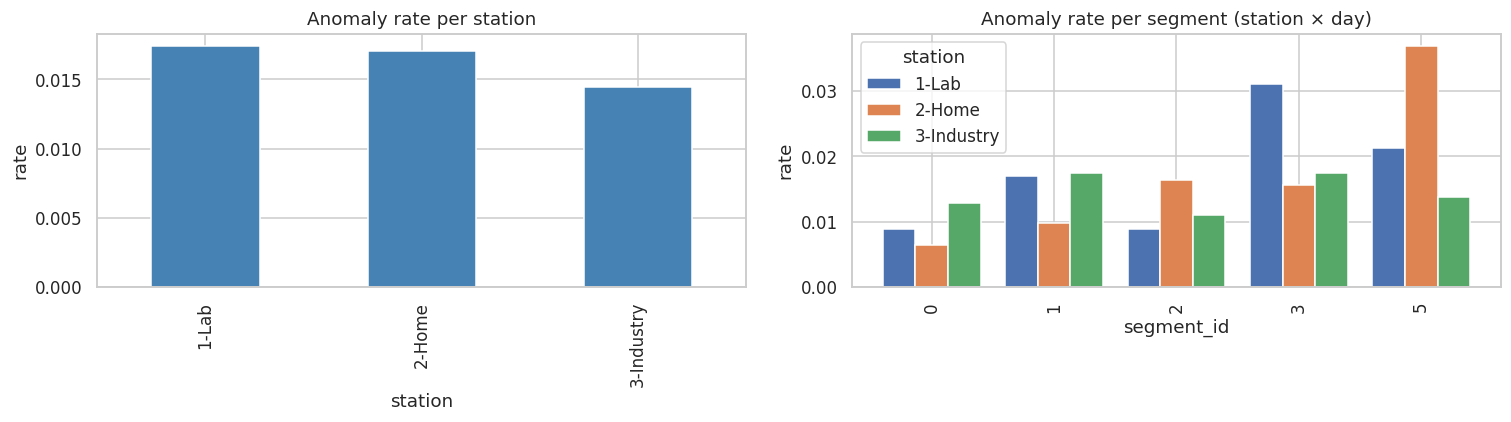

In [39]:
print("\nOverall anomaly rate:", round(df[TARGET].mean(), 4))

by_station = df.groupby("station")[TARGET].agg(["mean","sum","count"])
print("\nAnomaly rate per station:\n", by_station)

by_seg = df.groupby(["station","segment_id"])[TARGET].mean().unstack()
print("\nAnomaly rate per segment:\n", by_seg.round(4))

# stacked bar visual
fig, ax = plt.subplots(1, 2, figsize=(14,4))
by_station["mean"].plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Anomaly rate per station"); ax[0].set_ylabel("rate")

by_seg.T.plot.bar(ax=ax[1], width=0.8)
ax[1].set_title("Anomaly rate per segment (station × day)")
ax[1].set_ylabel("rate"); ax[1].legend(title="station")
plt.tight_layout(); plt.show()

## Interpolation


% interpolated per station:
station
1-Lab         0.0017
2-Home        0.0022
3-Industry    0.0026
Name: is_interpolated, dtype: float64

gap_length_s > 0:
count    2506.000000
mean       10.856345
std        20.534828
min         1.000000
25%         1.000000
50%         1.000000
75%         5.000000
max        74.000000
Name: gap_length_s, dtype: float64


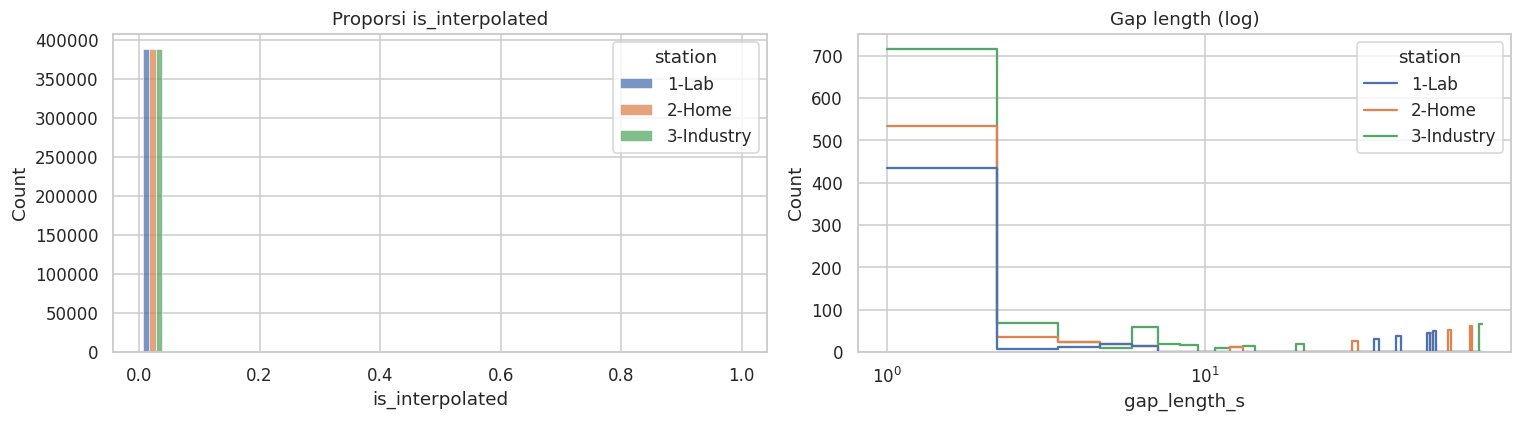


Anomaly rate by is_interpolated:
is_interpolated
0.0    0.0153
1.0    0.4757
Name: anomaly, dtype: float64


In [40]:
print("\n% interpolated per station:")
print(df.groupby("station")["is_interpolated"].mean().round(4))

print("\ngap_length_s > 0:")
print(df.loc[df["gap_length_s"]>0, "gap_length_s"].describe())

fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.histplot(data=df, x="is_interpolated", hue="station",
             multiple="dodge", shrink=0.7, ax=ax[0])
ax[0].set_title("Proporsi is_interpolated")

gaps = df[df["gap_length_s"]>0]
sns.histplot(data=gaps, x="gap_length_s", hue="station",
             bins=60, element="step", fill=False, ax=ax[1])
ax[1].set_xscale("log"); ax[1].set_title("Gap length (log)")
plt.tight_layout(); plt.show()

# Interpolasi vs anomaly — apakah gap berkorelasi dengan label?
print("\nAnomaly rate by is_interpolated:")
print(df.groupby("is_interpolated")[TARGET].mean().round(4))


## Feat Descriptive

In [45]:
def feat_stats(s: pd.Series) -> pd.Series:
    s = s.dropna()
    return pd.Series({
        "n": s.size,
        "mean": s.mean(), "std": s.std(),
        "min": s.min(),
        "p01": s.quantile(.01), "p05": s.quantile(.05),
        "p25": s.quantile(.25), "p50": s.median(),
        "p75": s.quantile(.75), "p95": s.quantile(.95),
        "p99": s.quantile(.99), "max": s.max(),
        "skew": s.skew(), "kurt": s.kurt(),
        "zero_%": (s == 0).mean() * 100,
    })

FEATS = ELEC + DERIVED + [ENERGY]
desc_by_station = (
    df.groupby("station")[FEATS]
      .apply(lambda g: g.apply(feat_stats).T)
)
print("\n=== Deskriptif per stasiun ===")
print(desc_by_station.round(4))


=== Deskriptif per stasiun ===
                                 n        mean       std         min         p01         p05         p25         p50         p75         p95         p99  \
station                                                                                                                                                    
1-Lab      voltage_V      388104.0    216.7559    7.8233      0.0000    210.7854    212.5294    214.8833    216.9902    219.0941    221.4788    223.1149   
           current_A      388039.0      3.2748    1.7919      0.0000      0.8455      1.0959      1.8790      2.9389      4.1080      7.0417      8.1842   
           power_W        388699.0    672.4687  364.0462      0.0000    173.5319    225.2788    385.0205    607.3251    849.0271   1430.1981   1667.4139   
           frequency_Hz   388308.0     50.0004    0.0937     49.7566     49.7932     49.8818     49.9114     49.9999     50.0881     50.1228     50.2077   
           power_factor   388596

## KDE per Station

/tmp/ipykernel_18944/1496519922.py:9: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  if f in logx_for: ax.set_xscale("log")


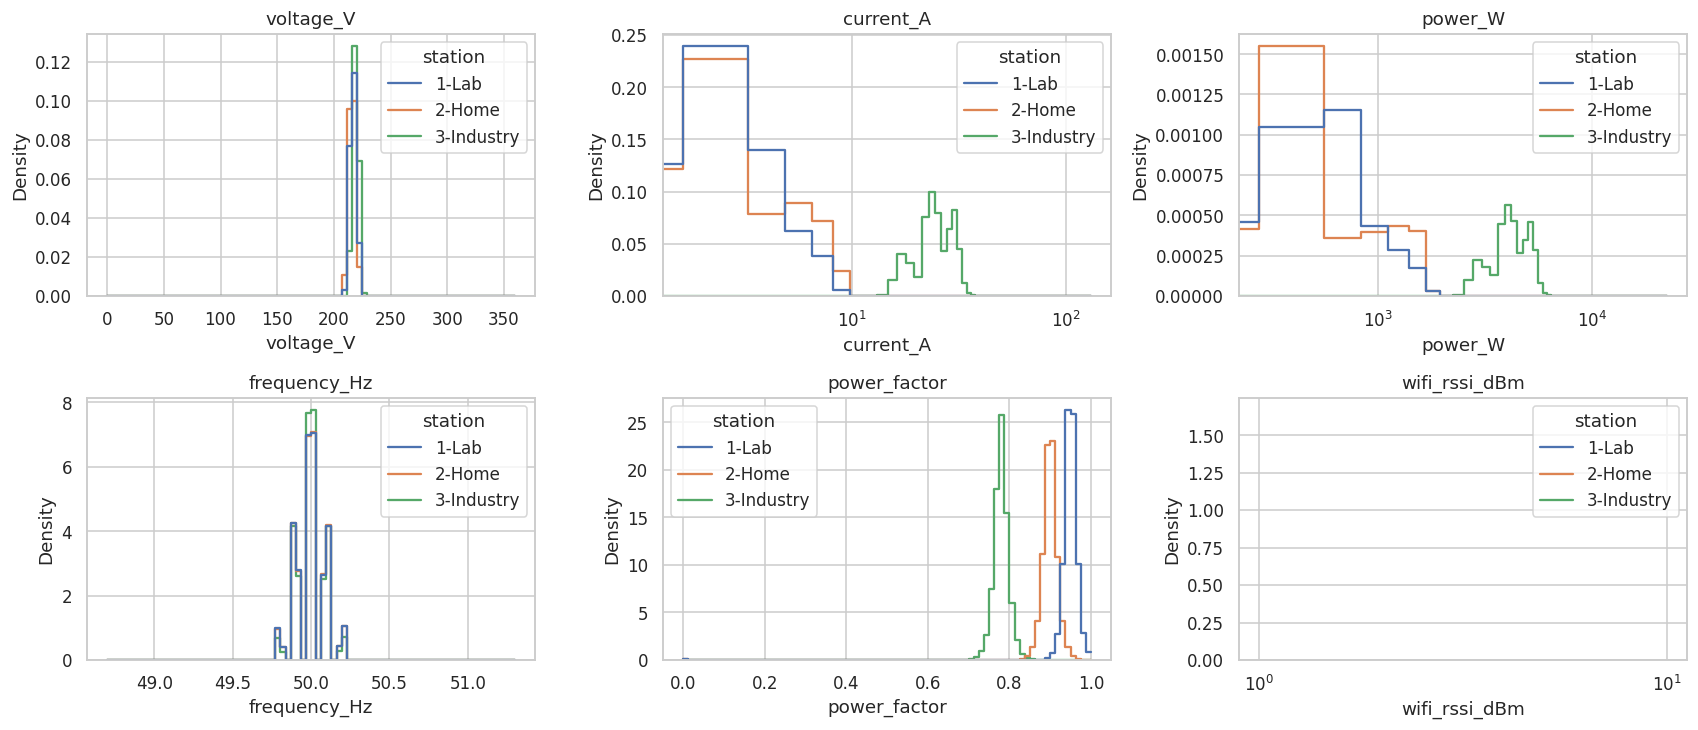

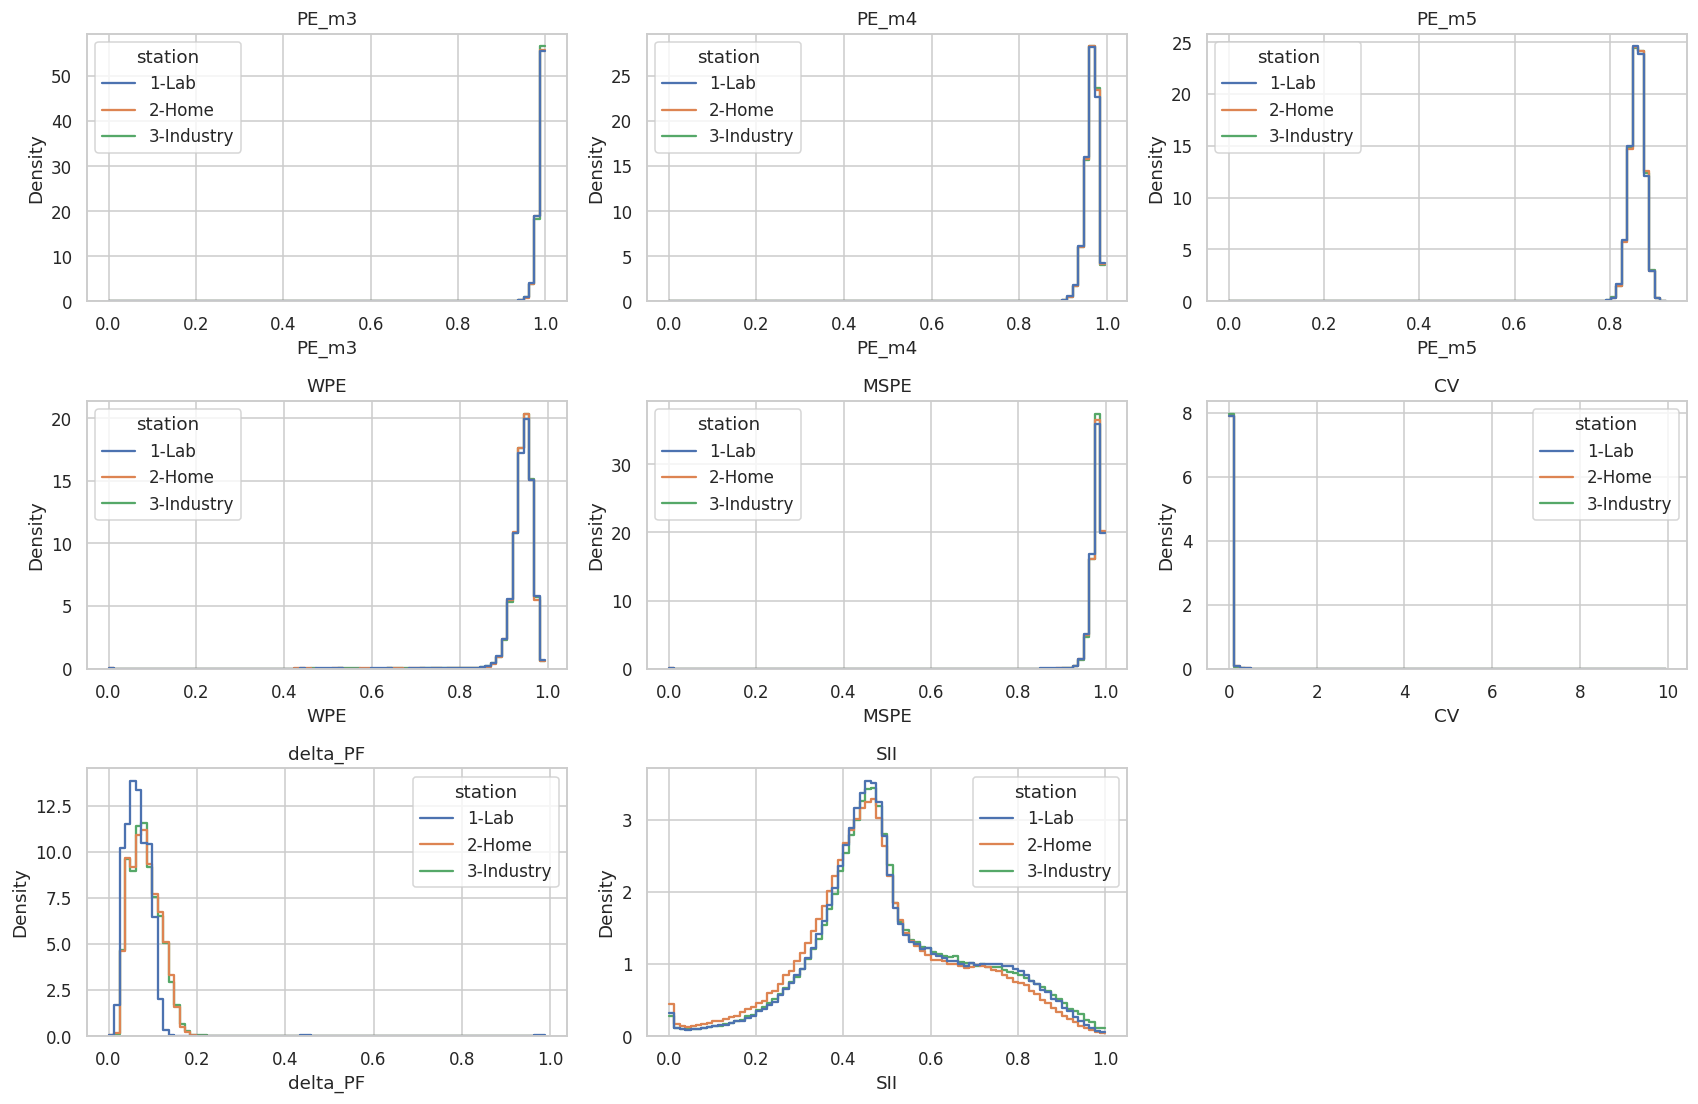

In [46]:
def plot_hist_by_station(features, ncols=3, logx_for=()):
    n = len(features); nrows = int(np.ceil(n/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 3.4*nrows))
    axes = np.array(axes).reshape(-1)
    for ax, f in zip(axes, features):
        sns.histplot(data=df, x=f, hue="station",
                     stat="density", common_norm=False,
                     bins=80, element="step", fill=False, ax=ax)
        if f in logx_for: ax.set_xscale("log")
        ax.set_title(f)
    for ax in axes[n:]: ax.axis("off")
    plt.tight_layout(); plt.show()

plot_hist_by_station(
    ELEC,
    logx_for=("power_W","current_A","wifi_rssi_dBm"),
)
plot_hist_by_station(DERIVED)

## Segment Distribution

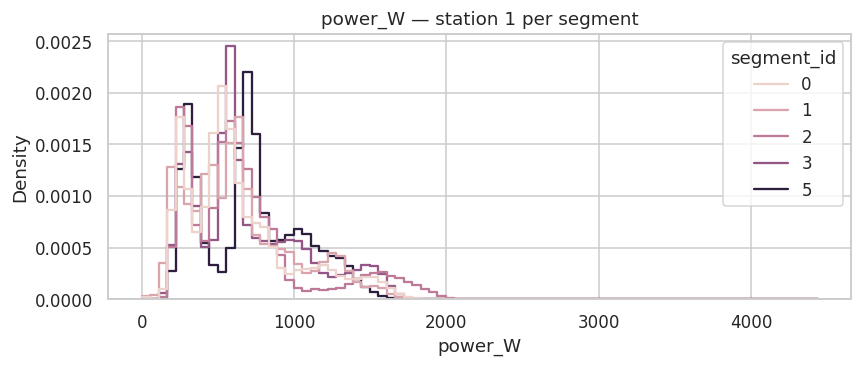

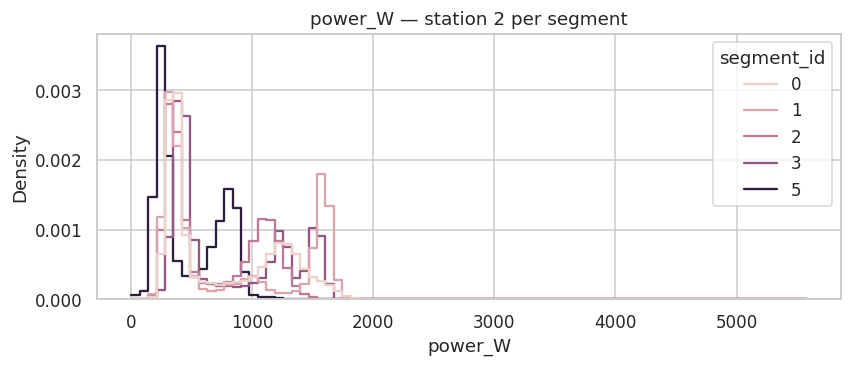

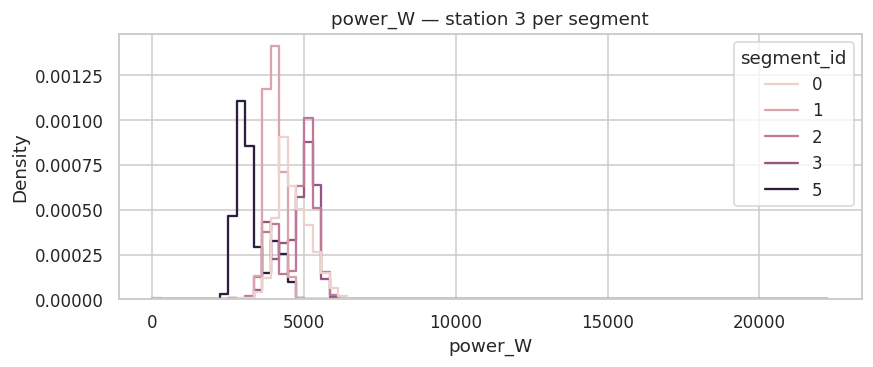

In [47]:
def segment_distribution(feature, station_id, bins=60):
    sub = df[df["station_id"] == station_id]
    fig, ax = plt.subplots(figsize=(8,3.5))
    sns.histplot(data=sub, x=feature, hue="segment_id",
                 stat="density", common_norm=False,
                 bins=bins, element="step", fill=False, ax=ax)
    ax.set_title(f"{feature} — station {station_id} per segment")
    plt.tight_layout(); plt.show()

for s in [1,2,3]:
    segment_distribution("power_W", s, bins=80)

## Conditional Distribution

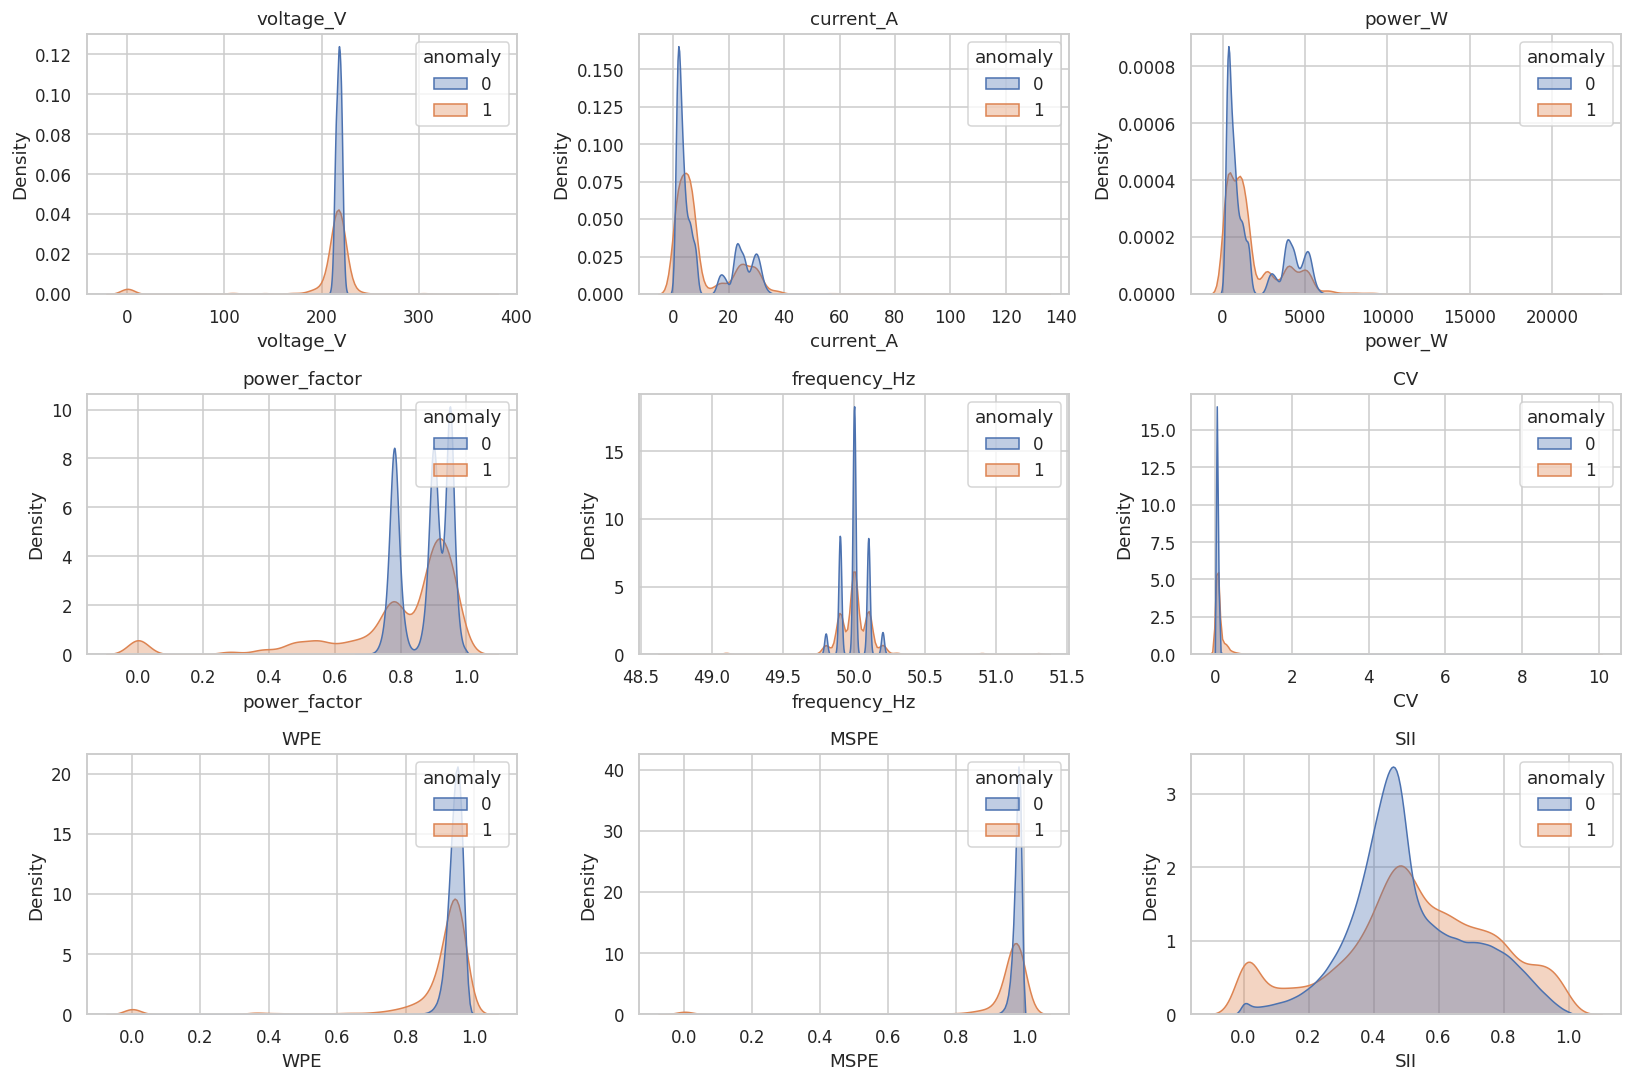

anomaly              0           1
voltage_V     217.4362   216.36385
current_A       4.7075     5.85680
power_W       948.0309  1123.30145
power_factor    0.8999     0.88020
frequency_Hz   50.0000    50.00060
CV              0.0482     0.06210
WPE             0.9461     0.93530
MSPE            0.9806     0.97210
SII             0.4769     0.52060


In [ ]:
# sep_feats = ["voltage_V","current_A","power_W",
#              "power_factor","frequency_Hz",
#              "CV","WPE","MSPE","SII"]
# fig, axes = plt.subplots(3, 3, figsize=(15,10))
# for ax, f in zip(axes.ravel(), sep_feats):
#     sns.kdeplot(data=df, x=f, hue=TARGET,
#                 common_norm=False, fill=True, alpha=.35, ax=ax)
#     ax.set_title(f)
# plt.tight_layout(); plt.show()

# # ringkasan median per kelas
# print(df.groupby([TARGET])[sep_feats].median().T)

## Distribution Test

In [50]:
from scipy import stats

# (a) perbedaan distribusi antar stasiun
print("\nKruskal–Wallis across stations (p-value):")
for f in FEATS:
    groups = [g[f].dropna().values for _, g in df.groupby("station_id")]
    try:
        h, p = stats.kruskal(*groups)
        print(f"{f:15s} p = {p:.2e}")
    except ValueError:
        print(f"{f:15s} skipped (constant)")

# (b) normality sample per stasiun (Jarque–Bera, ambil 5000 titik)
print("\nJarque–Bera (sample 5k) p-value — kecil = tidak normal:")
for f in FEATS:
    row = []
    for s, g in df.groupby("station_id"):
        x = g[f].dropna().sample(min(5000, g[f].notna().sum()), random_state=0)
        p = stats.jarque_bera(x).pvalue
        row.append(f"{s}:{p:.1e}")
    print(f"{f:15s} " + "  ".join(row))


Kruskal–Wallis across stations (p-value):
voltage_V       p = 0.00e+00
current_A       p = 0.00e+00
power_W         p = 0.00e+00
frequency_Hz    p = 4.08e-01
power_factor    p = 0.00e+00
wifi_rssi_dBm   p = 0.00e+00
PE_m3           p = 1.20e-10
PE_m4           p = 1.36e-30
PE_m5           p = 3.78e-20
WPE             p = 6.17e-08
MSPE            p = 2.65e-44
CV              p = 0.00e+00
delta_PF        p = 0.00e+00
SII             p = 0.00e+00
energy_kWh      p = 0.00e+00

Jarque–Bera (sample 5k) p-value — kecil = tidak normal:
voltage_V       1:0.0e+00  2:0.0e+00  3:0.0e+00
current_A       1:3.1e-193  2:7.4e-118  3:0.0e+00
power_W         1:2.4e-141  2:2.3e-132  3:8.4e-66
frequency_Hz    1:0.0e+00  2:0.0e+00  3:2.9e-01
power_factor    1:0.0e+00  2:0.0e+00  3:0.0e+00
wifi_rssi_dBm   1:0.0e+00  2:0.0e+00  3:5.8e-268
PE_m3           1:0.0e+00  2:0.0e+00  3:0.0e+00
PE_m4           1:0.0e+00  2:0.0e+00  3:0.0e+00
PE_m5           1:0.0e+00  2:0.0e+00  3:0.0e+00
WPE             1:0.0e+00  2

In [52]:
# energy_kWh: harus monoton naik & nilai awal berbeda per stasiun
print("\nNilai awal energy_kWh per (station, segment):")
print(df.groupby(["station","segment_id"])[ENERGY].first().unstack().round(3))

mono = df.groupby(["station_id","segment_id"])[ENERGY] \
         .apply(lambda s: (s.diff().dropna() >= 0).all())
print("\nMonoton naik di semua segmen:", mono.all())

# voltage & frequency vs nominal
for f, nom in [("voltage_V",220.0), ("frequency_Hz",50.0)]:
    dev = (df[f] - nom).abs()
    print(f"\n{f} deviasi dari {nom}:")
    print(pd.DataFrame({
        "p50": dev.groupby(df["station"]).median(),
        "p95": dev.groupby(df["station"]).quantile(.95),
        "p99": dev.groupby(df["station"]).quantile(.99),
        "max": dev.groupby(df["station"]).max(),
    }).round(3))

# kolom yang konstan per grup (kandidat di-drop)
const = {}
for (st, seg), g in df.groupby(["station_id","segment_id"]):
    const[f"{st}-{seg}"] = [c for c in FEATS if g[c].nunique() <= 1]
print("\nKolom konstan per grup:")
for k,v in const.items():
    if v: print(" ", k, v)


Nilai awal energy_kWh per (station, segment):
segment_id          0          1          2          3          5
station                                                          
1-Lab        1000.000   1015.262   1030.639   1046.909   1078.490
2-Home       5000.000   5017.795   5037.435   5053.636   5090.063
3-Industry  20000.001  20111.696  20207.520  20321.963  20544.506

Monoton naik di semua segmen: True

voltage_V deviasi dari 220.0:
              p50    p95     p99    max
station                                
1-Lab       3.099  7.494   9.316  220.0
2-Home      4.043  8.736  10.661  220.0
3-Industry  1.945  5.176   6.815  220.0

frequency_Hz deviasi dari 50.0:
              p50    p95    p99    max
station                               
1-Lab       0.088  0.199  0.212  1.300
2-Home      0.088  0.199  0.212  0.928
3-Industry  0.026  0.193  0.208  1.300

Kolom konstan per grup:


# Testing Set vs Training Set

In [57]:
test = test_df
print("Segmen train :", sorted(df["segment_id"].unique()))
print("Segmen test  :", sorted(test["segment_id"].unique()))
print("Stasiun train:", sorted(df["station_id"].unique()))
print("Stasiun test :", sorted(test["station_id"].unique()))

# Rentang waktu — apakah train & test berurutan atau tumpang tindih?
print("Train waktu:", df["timestamp"].min(), "→", df["timestamp"].max())
print("Test waktu :", test["timestamp"].min(), "→", test["timestamp"].max())

Segmen train : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(5)]
Segmen test  : [np.int64(4), np.int64(6)]
Stasiun train: [np.int64(1), np.int64(2), np.int64(3)]
Stasiun test : [np.int64(1), np.int64(2), np.int64(3)]
Train waktu: 2026-02-09 00:00:00 → 2026-02-14 23:59:59
Test waktu : 2026-02-13 00:00:00 → 2026-02-15 23:59:59


## Coverage shift

In [58]:
train_keys = set(map(tuple, df[["station_id","segment_id"]].drop_duplicates().values))
test_keys  = set(map(tuple, test[["station_id","segment_id"]].drop_duplicates().values))
print("Only in train:", sorted(train_keys - test_keys))
print("Only in test :", sorted(test_keys - train_keys))
print("Both         :", sorted(train_keys & test_keys))

Only in train: [(np.int64(1), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(1), np.int64(2)), (np.int64(1), np.int64(3)), (np.int64(1), np.int64(5)), (np.int64(2), np.int64(0)), (np.int64(2), np.int64(1)), (np.int64(2), np.int64(2)), (np.int64(2), np.int64(3)), (np.int64(2), np.int64(5)), (np.int64(3), np.int64(0)), (np.int64(3), np.int64(1)), (np.int64(3), np.int64(2)), (np.int64(3), np.int64(3)), (np.int64(3), np.int64(5))]
Only in test : [(np.int64(1), np.int64(4)), (np.int64(1), np.int64(6)), (np.int64(2), np.int64(4)), (np.int64(2), np.int64(6)), (np.int64(3), np.int64(4)), (np.int64(3), np.int64(6))]
Both         : []


## Covariate Shift

### KS-Test

In [59]:
from scipy.stats import ks_2samp

rows = []
for st in sorted(df["station_id"].unique()):
    tr = df[df["station_id"]==st]
    te = test[test["station_id"]==st] if st in test["station_id"].values else None
    if te is None or len(te) == 0:
        rows.append({"station": st, "feature": "—", "note": "stasiun tidak ada di test"})
        continue
    for f in FEATS:
        a = tr[f].dropna()
        b = te[f].dropna()
        if len(a) < 30 or len(b) < 30: continue
        stat, p = ks_2samp(a, b)
        rows.append({"station": st, "feature": f, "KS_stat": stat, "p": p})

ks_df = pd.DataFrame(rows)
shifted = ks_df[ks_df["p"] < 1e-3].sort_values("KS_stat", ascending=False)
print("Fitur dengan shift signifikan (p<1e-3):")
print(shifted.head(30))

Fitur dengan shift signifikan (p<1e-3):
    station        feature   KS_stat              p
44        3     energy_kWh  0.800308   0.000000e+00
29        2     energy_kWh  0.800168   0.000000e+00
14        1     energy_kWh  0.800124   0.000000e+00
35        3  wifi_rssi_dBm  0.648788   0.000000e+00
20        2  wifi_rssi_dBm  0.401745   0.000000e+00
42        3       delta_PF  0.223872   0.000000e+00
12        1       delta_PF  0.218866   0.000000e+00
27        2       delta_PF  0.214712   0.000000e+00
41        3             CV  0.213489   0.000000e+00
26        2             CV  0.210861   0.000000e+00
11        1             CV  0.209548   0.000000e+00
5         1  wifi_rssi_dBm  0.197169   0.000000e+00
43        3            SII  0.194667   0.000000e+00
32        3        power_W  0.187146   0.000000e+00
31        3      current_A  0.185021   0.000000e+00
28        2            SII  0.179173   0.000000e+00
13        1            SII  0.179026   0.000000e+00
17        2        power

## Population Stability Test

In [64]:
def psi(expected, actual, bins=20):
    expected, actual = expected.dropna(), actual.dropna()
    if len(expected) < 30 or len(actual) < 30: return np.nan
    # quantile-based binning pada expected
    qs = np.quantile(expected, np.linspace(0, 1, bins+1))
    qs = np.unique(qs)
    if len(qs) < 3: return np.nan
    e = np.histogram(expected, bins=qs)[0] / len(expected)
    a = np.histogram(actual,   bins=qs)[0] / len(actual)
    e = np.clip(e, 1e-6, None); a = np.clip(a, 1e-6, None)
    return np.sum((a - e) * np.log(a / e))


psi_rows = []
for st in sorted(df["station_id"].unique()):
    tr = df[df["station_id"]==st]
    te = test[test["station_id"]==st] if st in test["station_id"].values else None
    if te is None or len(te) == 0:
        psi_rows.append({"station": st, "feature": "—", "note": "stasiun tidak ada di test"})
        continue
    for f in FEATS:
        p = psi(tr[f], te[f])
        psi_rows.append({"station": st, "feature": f, "PSI": p})
psi_df = pd.DataFrame(psi_rows)
psi_df = psi_df.sort_values("PSI", ascending=False)
print("Fitur dengan PSI tinggi:")
print(psi_df.head(30))
# PSI < 0.1: stabil | 0.1–0.25: waspada | >0.25: shift serius

Fitur dengan PSI tinggi:
    station        feature        PSI
14        1     energy_kWh  11.317963
29        2     energy_kWh  11.313935
44        3     energy_kWh  11.312271
35        3  wifi_rssi_dBm   2.059781
5         1  wifi_rssi_dBm   1.778542
17        2        power_W   0.938059
16        2      current_A   0.807853
20        2  wifi_rssi_dBm   0.745276
31        3      current_A   0.698704
32        3        power_W   0.637294
42        3       delta_PF   0.428415
27        2       delta_PF   0.392722
12        1       delta_PF   0.384679
26        2             CV   0.375928
11        1             CV   0.361153
41        3             CV   0.346192
43        3            SII   0.295799
13        1            SII   0.276012
28        2            SII   0.266622
2         1        power_W   0.200588
1         1      current_A   0.192541
34        3   power_factor   0.069019
19        2   power_factor   0.064513
4         1   power_factor   0.056171
3         1   frequency_H

## Hours Test

In [62]:
df["hour"] = df["timestamp"].dt.hour
test["hour"] = test["timestamp"].dt.hour
# bandingkan distribusi jam
print(pd.concat([
    df["hour"].value_counts(normalize=True).rename("train"),
    test["hour"].value_counts(normalize=True).rename("test")
], axis=1).round(4))

       train    test
hour                
0     0.0417  0.0417
1     0.0417  0.0417
2     0.0417  0.0417
3     0.0417  0.0417
4     0.0417  0.0417
5     0.0417  0.0417
6     0.0417  0.0417
7     0.0417  0.0417
8     0.0417  0.0417
9     0.0417  0.0417
10    0.0417  0.0417
11    0.0417  0.0417
12    0.0417  0.0417
13    0.0417  0.0417
14    0.0417  0.0417
15    0.0417  0.0417
16    0.0417  0.0417
17    0.0417  0.0417
18    0.0417  0.0417
19    0.0417  0.0417
20    0.0417  0.0417
21    0.0417  0.0417
22    0.0417  0.0417
23    0.0417  0.0417


## Adversarial Testing

/tmp/ipykernel_18944/1606667925.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(frac=frac, random_state=seed))
/tmp/ipykernel_18944/1606667925.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(frac=frac, random_state=seed))


Subsample: (583200, 15) | train: 324,000 | test: 259,200
y balance (1=test): 0.4444
inf: 0 | NaN: 0
LR           adversarial AUC = 0.7539
HGB          adversarial AUC = 0.8961
LR-shuffle   adversarial AUC = 0.5011
→ noise floor: 0.501  (idealnya ≈0.50)

Top-15 adversarial-driving features:
rssi_weak       0.1958
delta_PF        0.0716
current_A       0.0675
power_W         0.0661
CV              0.0351
power_factor    0.0312
rssi_sat        0.0259
voltage_V       0.0175
SII             0.0156
frequency_Hz    0.0076
WPE             0.0017
PE_m3           0.0008
PE_m4           0.0003
PE_m5           0.0002
MSPE            0.0001


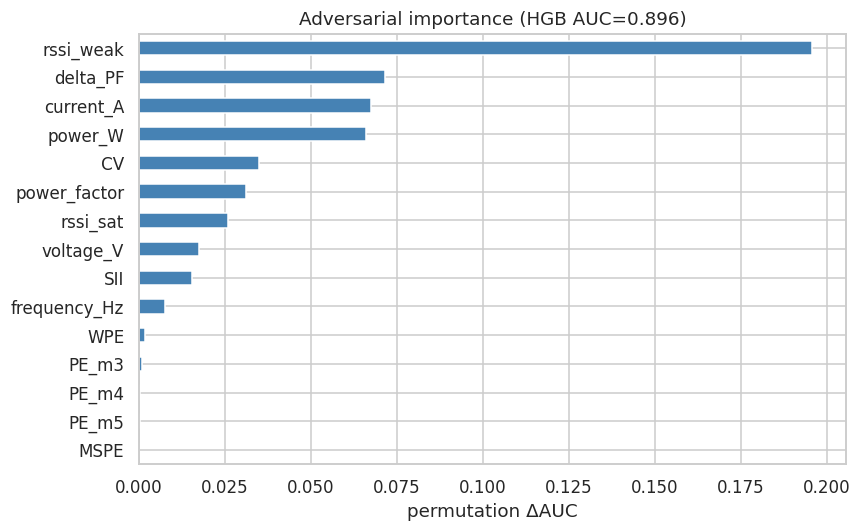

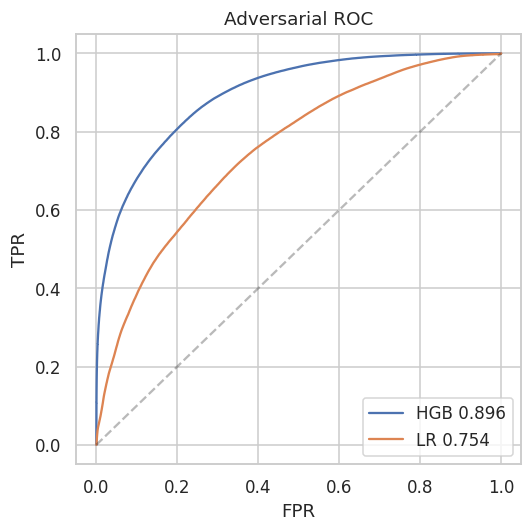


Per-station adversarial AUC:


/tmp/ipykernel_18944/1606667925.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(frac=frac, random_state=seed))
/tmp/ipykernel_18944/1606667925.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(frac=frac, random_state=seed))


  station 1: AUC = 0.6967 (n_tr=108,000, n_te=86,400)


/tmp/ipykernel_18944/1606667925.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(frac=frac, random_state=seed))
/tmp/ipykernel_18944/1606667925.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(frac=frac, random_state=seed))


  station 2: AUC = 0.7185 (n_tr=108,000, n_te=86,400)


/tmp/ipykernel_18944/1606667925.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(frac=frac, random_state=seed))
/tmp/ipykernel_18944/1606667925.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(frac=frac, random_state=seed))


  station 3: AUC = 0.8736 (n_tr=108,000, n_te=86,400)

🔴 AUC = 0.896 → shift BERAT.
   Aksi: jangan split acak; domain adaptation / rethink split.


In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance
import traceback

SEED = 42
rng  = np.random.RandomState(SEED)

# ------------------------------------------------------------
# 1) Feature selection (sama seperti sebelumnya)
# ------------------------------------------------------------
DROP = ["energy_kWh", "wifi_rssi_dBm"]
FEATS_BASE = [c for c in FEATS if c not in DROP]

for d in (df, test):
    d["rssi_sat"]  = (d["wifi_rssi_dBm"] <= -40.5).astype(np.int8)
    d["rssi_weak"] = (d["wifi_rssi_dBm"] <  -60.0).astype(np.int8)

FEATS_USE = FEATS_BASE + ["rssi_sat", "rssi_weak"]

# ------------------------------------------------------------
# 2) Cleaning + subsample per station
# ------------------------------------------------------------
def _clean(d):
    return d[FEATS_USE].replace([np.inf, -np.inf], np.nan).copy()

def _subsample_by_station(d, frac, seed=SEED):
    return (d.groupby("station_id", group_keys=False)
             .apply(lambda g: g.sample(frac=frac, random_state=seed))
             .reset_index(drop=True))

# ambil ~25% train, ~50% test — proporsi per stasiun terjaga
df_sub   = _subsample_by_station(df,   frac=0.25)
test_sub = _subsample_by_station(test, frac=0.50)

X_tr = _clean(df_sub).fillna(_clean(df).median())     # median dari full train
X_te = _clean(test_sub).fillna(_clean(df).median())

X = pd.concat([X_tr, X_te], ignore_index=True)
y = np.r_[np.zeros(len(X_tr), dtype=np.int8),
          np.ones(len(X_te),  dtype=np.int8)]

print(f"Subsample: {X.shape} | train: {len(X_tr):,} | test: {len(X_te):,}")
print(f"y balance (1=test): {y.mean():.4f}")
print(f"inf: {np.isinf(X.values).sum()} | NaN: {X.isna().sum().sum()}")

# ------------------------------------------------------------
# 3) run_cv — FIX: try/except, tanpa error_score
# ------------------------------------------------------------
def run_cv(clf, X, y, cv, name):
    try:
        proba = cross_val_predict(clf, X, y, cv=cv,
                                  method="predict_proba", n_jobs=-1)[:, 1]
        auc = roc_auc_score(y, proba)
        print(f"{name:12s} adversarial AUC = {auc:.4f}")
        return auc, proba
    except Exception as e:
        traceback.print_exc()
        print(f"{name} FAILED: {type(e).__name__}: {e}")
        return None, None

# ------------------------------------------------------------
# 4) Classifier
# ------------------------------------------------------------
clf_lr = Pipeline([
    ("sc", StandardScaler()),
    ("lr", LogisticRegression(max_iter=300, class_weight="balanced",
                              random_state=SEED, n_jobs=-1))
])
clf_hgb = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.05, max_depth=6,
    early_stopping=True, validation_fraction=0.1,
    random_state=SEED
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# --- Mode cepat: LR only (~1 menit) ---
auc_lr, p_lr = run_cv(clf_lr, X, y, cv, "LR")

# --- Mode utama: HGB (uncomment) ---
auc_hgb, p_hgb = run_cv(clf_hgb, X, y, cv, "HGB")

# ------------------------------------------------------------
# 5) Shuffle baseline — deteksi leakage (harus ~0.50)
# ------------------------------------------------------------
y_shuf = rng.permutation(y)
auc_shuf, _ = run_cv(clf_lr, X, y_shuf, cv, "LR-shuffle")
if auc_shuf is not None:
    print(f"→ noise floor: {auc_shuf:.3f}  (idealnya ≈0.50)")

# ------------------------------------------------------------
# 6) Feature importance (dari HGB)
# ------------------------------------------------------------
if auc_hgb is not None:
    clf_hgb.fit(X, y)
    perm = permutation_importance(
        clf_hgb, X, y, n_repeats=2,
        random_state=SEED, n_jobs=-1, scoring="roc_auc",
    )
    imp = (pd.Series(perm.importances_mean, index=FEATS_USE)
             .sort_values(ascending=False))
    print("\nTop-15 adversarial-driving features:")
    print(imp.head(15).round(4).to_string())

    fig, ax = plt.subplots(figsize=(8, 5))
    imp.head(15).iloc[::-1].plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"Adversarial importance (HGB AUC={auc_hgb:.3f})")
    ax.set_xlabel("permutation ΔAUC")
    plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 7) ROC
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 5))
plotted = False
if p_hgb is not None:
    f, t, _ = roc_curve(y, p_hgb); ax.plot(f, t, label=f"HGB {auc_hgb:.3f}"); plotted = True
if p_lr is not None:
    f, t, _ = roc_curve(y, p_lr);  ax.plot(f, t, label=f"LR {auc_lr:.3f}");   plotted = True
ax.plot([0,1], [0,1], "k--", alpha=.3)
if plotted:
    ax.legend()
ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
ax.set_title("Adversarial ROC")
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 8) Per-station AUC (station shift bisa berbeda dari agregat)
# ------------------------------------------------------------
print("\nPer-station adversarial AUC:")
for st in sorted(df["station_id"].unique()):
    tr_s = _subsample_by_station(df.loc[df["station_id"]==st], 0.25)
    te_s = _subsample_by_station(test.loc[test["station_id"]==st], 0.50)
    if len(te_s) < 100 or len(tr_s) < 100:
        print(f"  station {st}: skipped (too small)"); continue

    med_s = _clean(df.loc[df["station_id"]==st]).median()
    Xs = pd.concat([_clean(tr_s).fillna(med_s),
                    _clean(te_s).fillna(med_s)], ignore_index=True)
    ys = np.r_[np.zeros(len(tr_s), dtype=np.int8),
               np.ones(len(te_s),  dtype=np.int8)]
    cv_s = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    try:
        p = cross_val_predict(clf_lr, Xs, ys, cv=cv_s,
                              method="predict_proba", n_jobs=-1)[:, 1]
        print(f"  station {st}: AUC = {roc_auc_score(ys, p):.4f} "
              f"(n_tr={len(tr_s):,}, n_te={len(te_s):,})")
    except Exception as e:
        print(f"  station {st}: FAILED {type(e).__name__}: {e}")

# ------------------------------------------------------------
# 9) Verdict
# ------------------------------------------------------------
main_auc = next((a for a in [auc_hgb, auc_lr] if a is not None), None)
print("\n" + "="*60)
if main_auc is None:
    print("❌ All classifiers failed — lihat traceback di atas.")
elif main_auc < 0.55:
    print(f"✅ AUC = {main_auc:.3f} → TIDAK ADA shift bermakna.")
    print("   Aksi: GroupKFold(segment_id) langsung OK.")
elif main_auc < 0.65:
    print(f"🟡 AUC = {main_auc:.3f} → shift RINGAN.")
    print("   Aksi: GroupKFold + per-segment baseline subtraction.")
elif main_auc < 0.75:
    print(f"🟠 AUC = {main_auc:.3f} → shift SEDANG.")
    print("   Aksi: drop top-3 adversarial features, per-segment normalization.")
else:
    print(f"🔴 AUC = {main_auc:.3f} → shift BERAT.")
    print("   Aksi: jangan split acak; domain adaptation / rethink split.")
print("="*60)

# Missing Analysis

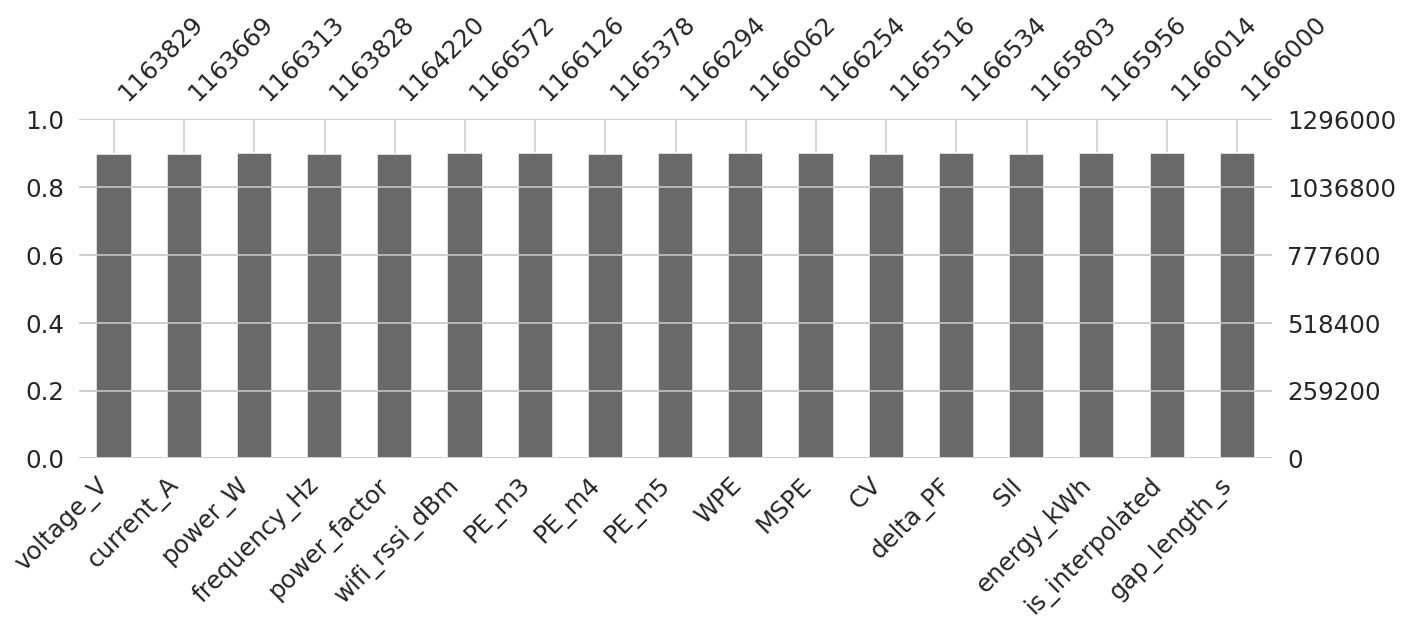

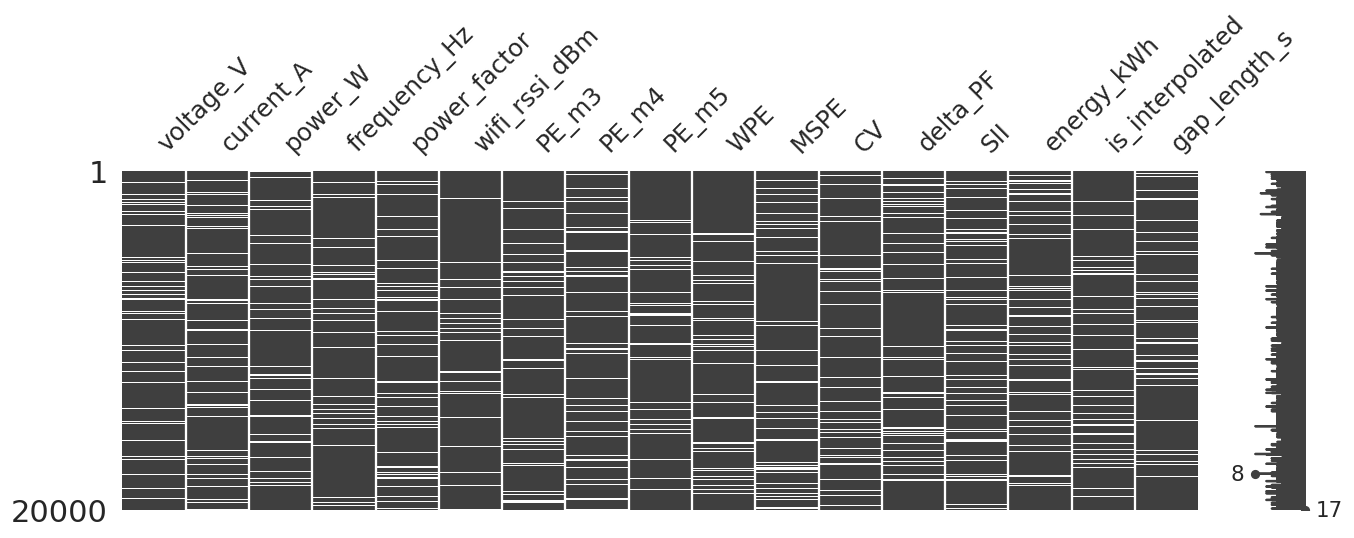

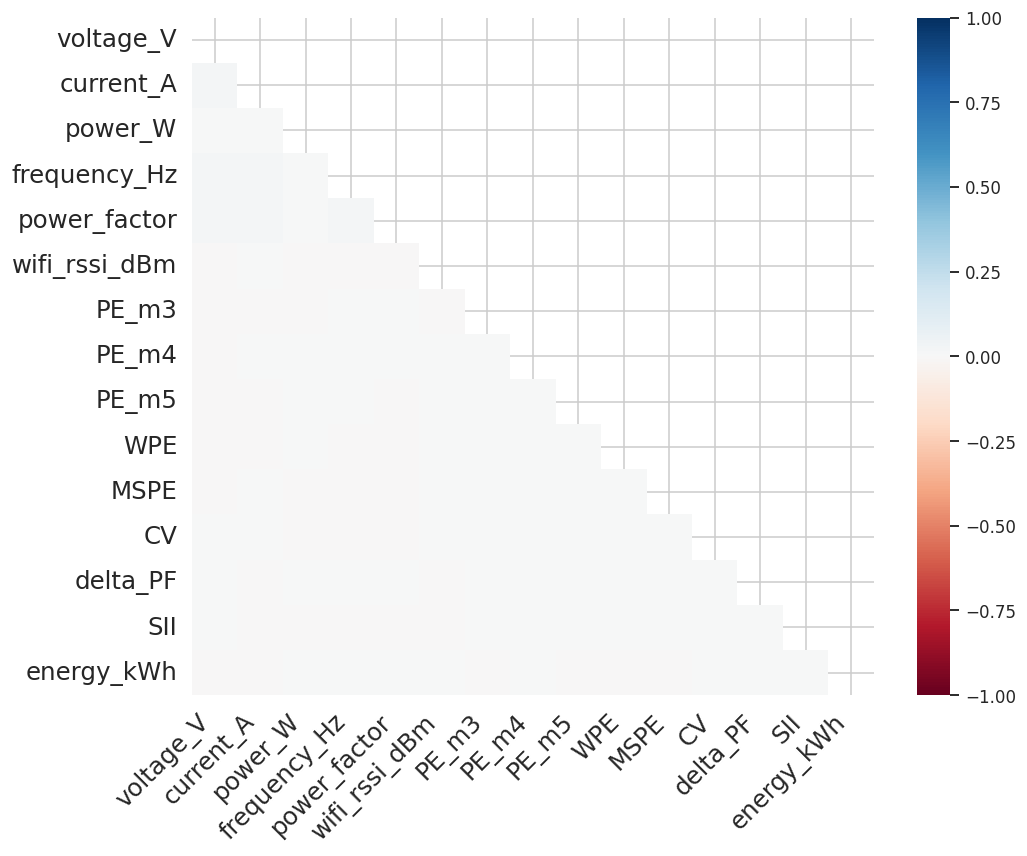

In [67]:
import missingno as msno
import matplotlib.pyplot as plt

FEATS_CHECK = FEATS + ["is_interpolated", "gap_length_s"]

# (a) Bar: % present per kolom
msno.bar(df[FEATS_CHECK], figsize=(14, 4))
plt.show()

# (b) Matrix: row-wise vs column-wise?
# Sample agar render cepat — pakai sort biar pola terlihat
msno.matrix(df[FEATS_CHECK].sample(20000, random_state=42), figsize=(14, 4))
plt.show()

# (c) Heatmap: fitur mana yang bolong bersamaan?
msno.heatmap(df[FEATS], figsize=(10, 8))
plt.show()

In [68]:
FEATS = [c for c in FEATS if c not in ["energy_kWh", "wifi_rssi_dBm"]]
df["n_nan"]   = df[FEATS].isna().sum(axis=1)
df["any_nan"] = (df["n_nan"] > 0).astype(int)

print("=== Missingness per segmen (CRITICAL untuk shift) ===")
print(pd.crosstab(df["segment_id"], df["any_nan"], normalize="index").round(4))

print("\n=== Missingness per stasiun ===")
print(pd.crosstab(df["station_id"], df["any_nan"], normalize="index").round(4))

print("\n=== Missingness vs is_interpolated ===")
print(pd.crosstab(df["any_nan"], df["is_interpolated"], normalize="index").round(4))

print("\n=== Missingness vs anomaly ===")
print(pd.crosstab(df["any_nan"], df["anomaly"], normalize="index").round(4))

# Sama untuk test!
test["n_nan"]   = test[FEATS].isna().sum(axis=1)
test["any_nan"] = (test["n_nan"] > 0).astype(int)
print("\n=== TEST: missingness per segmen ===")
print(pd.crosstab(test["segment_id"], test["any_nan"], normalize="index").round(4))

=== Missingness per segmen (CRITICAL untuk shift) ===
any_nan          0       1
segment_id                
0           0.2526  0.7474
1           0.2532  0.7468
2           0.2550  0.7450
3           0.2533  0.7467
5           0.2537  0.7463

=== Missingness per stasiun ===
any_nan          0       1
station_id                
1           0.2534  0.7466
2           0.2537  0.7463
3           0.2536  0.7464

=== Missingness vs is_interpolated ===
is_interpolated     0.0     1.0
any_nan                        
0                1.0000  0.0000
1                0.9971  0.0029

=== Missingness vs anomaly ===
anomaly       0       1
any_nan                
0        0.9850  0.0150
1        0.9832  0.0168

=== TEST: missingness per segmen ===
any_nan          0       1
segment_id                
4           0.2529  0.7471
6           0.2530  0.7470


In [69]:
# Kalau anomaly rate berbeda tajam antara any_nan=0 vs 1
# maka missingness itu sendiri = prediktor, bukan nuisance
print(df.groupby("any_nan")["anomaly"].agg(["mean", "size"]))

             mean    size
any_nan                  
0        0.014982  328598
1        0.016768  967402


# Preprocessing

In [99]:
import numpy as np
import pandas as pd
import warnings
from sklearn.preprocessing import RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin

warnings.filterwarnings("ignore")


class PowerAnomalyPreprocessor(BaseEstimator, TransformerMixin):
    """Preprocessing dengan fitur relative (A) & temporal (B)."""

    ELECTRICAL = ["voltage_V", "current_A", "power_W", "frequency_Hz"]
    
    # Fitur dasar untuk imputasi
    IMPUTE_FEATS = [
        "voltage_V", "current_A", "power_W", "frequency_Hz",
        "power_factor", "PE_m3", "PE_m4", "PE_m5", "WPE", "MSPE",
        "delta_PF_log", "SII",
    ]
    
    def __init__(
        self,
        drop_cols=("energy_kWh", "wifi_rssi_dBm"),
        scale_feats=("power_factor", "delta_PF_log", "SII"),
        roll_feats=("power_W", "current_A", "voltage_V", "frequency_Hz", "CV", "power_factor"), # <-- Tambah power_factor
        temporal_feats=("voltage_V", "current_A", "power_W", "frequency_Hz"),
        pe_feats=("PE_m3", "PE_m4", "PE_m5", "WPE", "MSPE"),
        roll_window=300,          
        roll_min_periods=60,      
        ffill_limit=60,           
        clip_value=5.0,           
    ):
        self.drop_cols        = list(drop_cols)
        self.scale_feats      = list(scale_feats)
        self.roll_feats       = list(roll_feats)
        self.temporal_feats   = list(temporal_feats)
        self.pe_feats         = list(pe_feats)
        self.roll_window      = roll_window
        self.roll_min_periods = roll_min_periods
        self.ffill_limit      = ffill_limit
        self.clip_value       = clip_value

    def _sort(self, d):
        return d.sort_values(
            ["station_id", "segment_id", "timestamp"]
        ).reset_index(drop=True)

    def _create_flags(self, d):
        d = d.copy()
        for ch in ["voltage_V", "current_A", "power_W", "power_factor"]:
            d[f"{ch}_zero"] = (d[ch] == 0).astype(np.int8)
        
        if "is_interpolated" in d.columns:
            d["was_interpolated"] = d["is_interpolated"].fillna(0).round().astype(np.int8)
            d["interp_status_unknown"] = d["is_interpolated"].isna().astype(np.int8)
        else:
            d["was_interpolated"] = np.int8(0)
            d["interp_status_unknown"] = np.int8(1)
        
        d["elec_missing"] = d[self.ELECTRICAL].isna().all(axis=1).astype(np.int8)
        
        d["cv_high"]     = (d["CV"] > 5.0).astype(np.int8)
        d["freq_off_02"] = ((d["frequency_Hz"] - 50).abs() > 0.2).astype(np.int8)
        d["freq_off_05"] = ((d["frequency_Hz"] - 50).abs() > 0.5).astype(np.int8)
        d["volt_sag"]    = (d["voltage_V"] < 200).astype(np.int8)
        d["volt_swell"]  = (d["voltage_V"] > 240).astype(np.int8)
        return d

    def _transform_dist(self, d):
        d = d.copy()
        d["CV_capped"] = d["CV"].replace([np.inf, -np.inf], np.nan).clip(lower=0, upper=9.95)
        d["CV_log"] = np.log1p(d["CV_capped"])
        d["delta_PF_log"] = np.log1p(d["delta_PF"].replace([np.inf, -np.inf], np.nan).clip(lower=0))
        return d

    def _ffill(self, d):
        for f in self.IMPUTE_FEATS:
            if f in d.columns:
                d[f] = d.groupby(["station_id", "segment_id"])[f].ffill(limit=self.ffill_limit)
        return d

    def _rolling_features(self, d):
        # Jalur A: Rolling Baseline Subtraction (Relative)
        # TAMBAHAN: "power_factor" dimasukkan ke sini!
        for f in self.roll_feats:
            roll = d.groupby(["station_id", "segment_id"])[f].transform(
                lambda s: s.rolling(self.roll_window, min_periods=self.roll_min_periods).median()
            )
            d[f"{f}_rel"] = (d[f] - roll).fillna(0.0)
        return d

    def _temporal_features(self, d):
        # Jalur B: Temporal Dynamics (Std & Diff)
        for f in self.temporal_feats:
            g = d.groupby(["station_id", "segment_id"])[f]
            
            # Tambahan window 300s (5 menit)
            for w in [5, 30, 300]:
                d[f"{f}_std_{w}s"] = g.transform(lambda s: s.rolling(w, min_periods=1).std()).fillna(0.0).clip(0, 50)
            
            # Diff pendek (1 detik) dan panjang (60 detik / 1 menit)
            d[f"{f}_diff"] = g.diff().fillna(0.0).clip(-10, 10)
            d[f"{f}_diff_60s"] = g.diff(60).fillna(0.0).clip(-10, 10)
            
        return d

    def _prepare(self, d):
        d = self._sort(d)
        d = self._create_flags(d)        
        d = self._transform_dist(d)      
        d = self._ffill(d)               
        d = self._rolling_features(d)    
        d = self._temporal_features(d)   # <-- Tambahan Jalur B
        return d

    def _impute_medians(self, d):
        d = d.copy()
        for st in d["station_id"].unique():
            mask = (d["station_id"] == st).values
            med = self.station_medians_.loc[st] if st in self.station_medians_.index else self.station_medians_.median()
            d.loc[mask, self.IMPUTE_FEATS] = d.loc[mask, self.IMPUTE_FEATS].fillna(med)
        return d

    def _apply_scalers(self, d):
        for f in self.scale_feats:
            d[f"{f}_sc"] = 0.0
        for st in d["station_id"].unique():
            if st not in self.scalers_: continue
            mask = (d["station_id"] == st).values
            sc = self.scalers_[st]
            scaled = sc.transform(d.loc[mask, self.scale_feats].to_numpy())
            for i, f in enumerate(self.scale_feats):
                d.loc[mask, f"{f}_sc"] = scaled[:, i]
        for f in self.scale_feats:
            d[f"{f}_sc"] = d[f"{f}_sc"].clip(-self.clip_value, self.clip_value)
        return d

    def _apply_roll_scalers(self, d):
        for f in self.roll_feats:
            col = f"{f}_rel"
            d[f"{col}_sc"] = 0.0
            for st in d["station_id"].unique():
                key = (int(st), f)
                if key not in self.roll_scalers_: continue
                mask = (d["station_id"] == st).values
                sc = self.roll_scalers_[key]
                d.loc[mask, f"{col}_sc"] = sc.transform(d.loc[mask, [col]].to_numpy()).ravel()
            d[f"{col}_sc"] = d[f"{col}_sc"].clip(-self.clip_value, self.clip_value)
        return d
        
    def _apply_temporal_scalers(self, d):
        # Scaling untuk fitur temporal
        temporal_cols = []
        for f in self.temporal_feats:
            temporal_cols.extend([f"{f}_std_5s", f"{f}_std_30s", f"{f}_diff"])
            
        for col in temporal_cols:
            d[f"{col}_sc"] = 0.0
            for st in d["station_id"].unique():
                key = (int(st), col)
                if key not in self.temporal_scalers_: continue
                mask = (d["station_id"] == st).values
                sc = self.temporal_scalers_[key]
                d.loc[mask, f"{col}_sc"] = sc.transform(d.loc[mask, [col]].to_numpy()).ravel()
            d[f"{col}_sc"] = d[f"{col}_sc"].clip(-self.clip_value, self.clip_value)
        return d

    def fit(self, df):
        d = self._prepare(df.copy())
        
        self.station_medians_ = d.groupby("station_id")[self.IMPUTE_FEATS].median()
        d = self._impute_medians(d)
        
        self.scalers_ = {}
        for st, g in d.groupby("station_id"):
            self.scalers_[st] = RobustScaler().fit(g[self.scale_feats])
        
        self.roll_scalers_ = {}
        for st, g in d.groupby("station_id"):
            for f in self.roll_feats:
                col = f"{f}_rel"
                valid = g[col].dropna().values.reshape(-1, 1)
                if len(valid) >= 10:
                    self.roll_scalers_[(int(st), f)] = RobustScaler().fit(valid)
                    
        self.temporal_scalers_ = {}
        for st, g in d.groupby("station_id"):
            for f in self.temporal_feats:
                for col in [f"{f}_std_5s", f"{f}_std_30s", f"{f}_diff"]:
                    valid = g[col].dropna().values.reshape(-1, 1)
                    if len(valid) >= 10:
                        self.temporal_scalers_[(int(st), col)] = RobustScaler().fit(valid)
        
        self.feature_names_ = self._build_feature_names()
        return self

    def transform(self, df):
        d = self._prepare(df.copy())
        d = self._impute_medians(d)
        d = self._apply_scalers(d)
        d = self._apply_roll_scalers(d)
        d = self._apply_temporal_scalers(d)
        return d

    def _build_feature_names(self):
        flags = [
            "voltage_V_zero", "current_A_zero", "power_W_zero",
            "power_factor_zero", "was_interpolated", "interp_status_unknown", "elec_missing",
            "cv_high", "freq_off_02", "freq_off_05", "volt_sag", "volt_swell",
        ]
        scaled = [f"{f}_sc" for f in self.scale_feats]
        rolled = [f"{f}_rel_sc" for f in self.roll_feats]
        
        temporal = []
        for f in self.temporal_feats:
            temporal.extend([f"{f}_std_5s_sc", f"{f}_std_30s_sc", f"{f}_diff_sc"])
            
        return list(self.pe_feats) + scaled + rolled + temporal + flags

    def get_feature_names_out(self):
        return self.feature_names_

In [79]:
# ---- Fit hanya di train ----
prep = PowerAnomalyPreprocessor()
prep.fit(df)

df_proc   = prep.transform(df)
test_proc = prep.transform(test)

FEATS_FINAL = prep.get_feature_names_out()
print(f"Final features ({len(FEATS_FINAL)}): {FEATS_FINAL}")

# Ambil X & y
X_train = df_proc[FEATS_FINAL].to_numpy()
y_train = df_proc["anomaly"].to_numpy()
X_test  = test_proc[FEATS_FINAL].to_numpy()
# y_test tidak ada (test.csv)

# Simpan juga segment_id untuk GroupKFold nanti
groups_train = df_proc["segment_id"].to_numpy()
groups_test  = test_proc["segment_id"].to_numpy()

# Simpan untuk modeling
np.savez_compressed(
    "preprocessed.npz",
    X_train=X_train, y_train=y_train, groups_train=groups_train,
    X_test=X_test, groups_test=groups_test,
    features=np.array(FEATS_FINAL),
)
print(f"\nShapes: train {X_train.shape} | test {X_test.shape}")

Final features (22): ['PE_m3', 'PE_m4', 'PE_m5', 'WPE', 'MSPE', 'power_factor_sc', 'delta_PF_log_sc', 'SII_sc', 'power_W_rel_sc', 'current_A_rel_sc', 'voltage_V_zero', 'current_A_zero', 'power_W_zero', 'power_factor_zero', 'was_interpolated', 'interp_status_unknown', 'elec_missing', 'cv_high', 'freq_off_02', 'freq_off_05', 'volt_sag', 'volt_swell']

Shapes: train (1296000, 22) | test (518400, 22)


In [80]:
def validate_pipeline(df_proc, test_proc, feats):
    print("=" * 60)
    print("VALIDATION REPORT")
    print("=" * 60)
    
    # (a) No NaN / Inf
    for name, d in [("train", df_proc), ("test", test_proc)]:
        n_nan = d[feats].isna().sum().sum()
        n_inf = np.isinf(d[feats].to_numpy()).sum()
        print(f"[{name:5s}] NaN: {n_nan:,} | Inf: {n_inf:,}")
        assert n_nan == 0 and n_inf == 0, f"{name}: masih ada NaN/Inf!"
    
    # (b) Distribusi flag (sanity)
    print("\nFlag distribution (% of rows):")
    flags = [f for f in feats if f.endswith(("_zero", "_missing",
                                              "was_interpolated"))]
    for f in flags:
        tr = df_proc[f].mean() * 100
        te = test_proc[f].mean() * 100
        print(f"  {f:25s} train={tr:6.2f}%  test={te:6.2f}%")
    
    # (c) Distribusi fitur final (mean / std / range)
    print("\nFeature stats (mean ± std | min … max):")
    for f in feats:
        tr_mean, tr_std = df_proc[f].mean(), df_proc[f].std()
        tr_min,  tr_max = df_proc[f].min(),  df_proc[f].max()
        print(f"  {f:25s} {tr_mean:+7.3f} ± {tr_std:.3f} | "
              f"[{tr_min:+7.3f}, {tr_max:+7.3f}]")
    
    # (d) Missingness cross-check (harus seragam train vs test)
    print("\nSanity: any-NaN pre-imputation (should be similar train vs test)")
    print("  (skip — dijamin oleh hasil missingno sebelumnya)")


validate_pipeline(df_proc, test_proc, FEATS_FINAL)

VALIDATION REPORT
[train] NaN: 0 | Inf: 0
[test ] NaN: 0 | Inf: 0

Flag distribution (% of rows):
  voltage_V_zero            train=  0.02%  test=  0.08%
  current_A_zero            train=  0.03%  test=  0.11%
  power_W_zero              train=  0.03%  test=  0.10%
  power_factor_zero         train=  0.03%  test=  0.11%
  was_interpolated          train=  0.19%  test=  0.23%
  elec_missing              train=  0.03%  test=  0.03%

Feature stats (mean ± std | min … max):
  PE_m3                      +0.988 ± 0.030 | [ +0.000,  +1.000]
  PE_m4                      +0.963 ± 0.033 | [ +0.000,  +0.996]
  PE_m5                      +0.856 ± 0.032 | [ +0.000,  +0.917]
  WPE                        +0.941 ± 0.044 | [ +0.000,  +0.995]
  MSPE                       +0.977 ± 0.031 | [ +0.000,  +0.999]
  power_factor_sc            -0.017 ± 0.910 | [ -5.000,  +5.000]
  delta_PF_log_sc            +0.066 ± 0.719 | [ -1.694,  +5.000]
  SII_sc                     +0.135 ± 0.788 | [ -2.072,  +2.351]
  pow

In [82]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

def adversarial_check(df_proc, test_proc, feats):
    X_tr = df_proc[feats].to_numpy()
    X_te = test_proc[feats].to_numpy()
    X = np.vstack([X_tr, X_te])
    y = np.r_[np.zeros(len(X_tr), dtype=np.int8),
              np.ones(len(X_te),  dtype=np.int8)]
    
    clf = HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, max_depth=6,
        early_stopping=True, random_state=SEED,
    )
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    proba = cross_val_predict(
        clf, X, y, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]
    auc = roc_auc_score(y, proba)
    
    print(f"\n{'='*60}")
    print(f"Adversarial AUC (post-preprocessing): {auc:.4f}")
    print(f"{'='*60}")
    
    if auc < 0.55:
        print("✅ AMAN — lanjut modeling dengan GroupKFold(segment_id)")
    elif auc < 0.65:
        print("🟡 Shift ringan — aman modeling, tapi monitor per-segmen")
    elif auc < 0.75:
        print("🟠 Shift sedang — perlu cek fitur mana yang masih drive shift")
    else:
        print("🔴 Shift masih berat — cek permutation importance")
    return auc


auc_after = adversarial_check(df_proc, test_proc, FEATS_FINAL)


Adversarial AUC (post-preprocessing): 0.6788
🟠 Shift sedang — perlu cek fitur mana yang masih drive shift


In [83]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
import pandas as pd, numpy as np

X_tr = df_proc[FEATS_FINAL].to_numpy()
X_te = test_proc[FEATS_FINAL].to_numpy()
X_all = np.vstack([X_tr, X_te])
y_all = np.r_[np.zeros(len(X_tr), dtype=np.int8),
              np.ones(len(X_te),  dtype=np.int8)]

Xa, Xb, ya, yb = train_test_split(
    X_all, y_all, test_size=0.3, stratify=y_all, random_state=42
)

clf = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.05, max_depth=6,
    early_stopping=True, random_state=42,
)
clf.fit(Xa, ya)

perm = permutation_importance(
    clf, Xb, yb, n_repeats=3, random_state=42, n_jobs=-1, scoring="roc_auc"
)
imp = (pd.Series(perm.importances_mean, index=FEATS_FINAL)
         .sort_values(ascending=False))
print("Top-10 adversarial drivers (post-preprocessing):")
print(imp.head(10).round(4).to_string())

Top-10 adversarial drivers (post-preprocessing):
delta_PF_log_sc     0.0919
SII_sc              0.0530
WPE                 0.0062
PE_m3               0.0054
PE_m5               0.0032
power_W_rel_sc      0.0024
current_A_rel_sc    0.0023
PE_m4               0.0018
power_factor_sc     0.0017
MSPE                0.0011


# Modelling & Submission

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    average_precision_score, precision_recall_curve,
    f1_score, precision_recall_fscore_support,
)

FEATS  = prep.get_feature_names_out()
X      = df_proc[FEATS].to_numpy()
y      = df_proc["anomaly"].to_numpy().astype(np.int8)
groups = df_proc["segment_id"].to_numpy()

# Clean mask (non-artefak)
artifact_mask = (
    (df_proc["voltage_V"] == 0) |
    (df_proc["current_A"] == 0) |
    (df_proc["power_W"]  == 0) |
    (df_proc["power_factor"] == 0) |
    (df_proc["was_interpolated"] == 1)
).to_numpy()
clean_mask = ~artifact_mask

base_rate_full  = y.mean()
base_rate_clean = y[clean_mask].mean()
print(f"Base rate FULL : {base_rate_full*100:.4f}%  (random PR-AUC ≈ {base_rate_full:.4f})")
print(f"Base rate CLEAN: {base_rate_clean*100:.4f}%  (random PR-AUC ≈ {base_rate_clean:.4f})")


def evaluate_pr(y_true, score, name, subset_mask=None):
    """PR-AUC centric evaluation. `subset_mask` opsional untuk subset evaluasi."""
    if subset_mask is not None:
        y_eval   = y_true[subset_mask]
        s_eval   = score[subset_mask]
    else:
        y_eval, s_eval = y_true, score

    if y_eval.sum() == 0 or y_eval.sum() == len(y_eval):
        return {"name": name, "PR_AUC": np.nan,
                "n": len(y_eval), "pos": int(y_eval.sum())}

    ap = average_precision_score(y_eval, s_eval)
    prec, rec, thr = precision_recall_curve(y_eval, s_eval)
    f1s = 2 * prec * rec / (prec + rec + 1e-12)
    best_f1 = f1s[:-1].max()
    best_idx = f1s[:-1].argmax()
    best_thr = thr[best_idx] if best_idx < len(thr) else 0.5
    return {
        "name": name, "n": len(y_eval), "pos": int(y_eval.sum()),
        "PR_AUC": ap, "F1_at_best": best_f1,
        "P_at_best": prec[best_idx], "R_at_best": rec[best_idx],
        "best_thr": best_thr,
    }


# ---- L0: Dummy (all-zero scores) ----
score_l0 = np.zeros(len(y))
r0_full  = evaluate_pr(y, score_l0, "L0 Dummy",
                       subset_mask=None)
r0_clean = evaluate_pr(y, score_l0, "L0 Dummy (clean)",
                       subset_mask=clean_mask)

# ---- L1: Rule (binary score) ----
score_l1 = artifact_mask.astype(np.float32)
r1_full  = evaluate_pr(y, score_l1, "L1 Rule",
                       subset_mask=None)
r1_clean = evaluate_pr(y, score_l1, "L1 Rule (clean)",
                       subset_mask=clean_mask)

for r in [r0_full, r1_full, r0_clean, r1_clean]:
    print(f"{r['name']:22s} n={r['n']:>9,}  pos={r['pos']:>6,}  "
          f"PR-AUC={r['PR_AUC']:.4f}  F1={r.get('F1_at_best', 0):.4f}")

Base rate FULL : 1.6315%  (random PR-AUC ≈ 0.0163)
Base rate CLEAN: 1.4788%  (random PR-AUC ≈ 0.0148)
L0 Dummy               n=1,296,000  pos=21,144  PR-AUC=0.0163  F1=0.0321
L1 Rule                n=1,296,000  pos=21,144  PR-AUC=0.0729  F1=0.1656
L0 Dummy (clean)       n=1,292,655  pos=19,116  PR-AUC=0.0148  F1=0.0291
L1 Rule (clean)        n=1,292,655  pos=19,116  PR-AUC=0.0148  F1=0.0291


In [116]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# 0. PREPROCESSOR (v11 - Deep Temporal Features)
# ============================================================
class PowerAnomalyPreprocessor(BaseEstimator, TransformerMixin):
    ELECTRICAL = ["voltage_V", "current_A", "power_W", "frequency_Hz"]
    IMPUTE_FEATS = ["voltage_V", "current_A", "power_W", "frequency_Hz", "power_factor", "PE_m3", "PE_m4", "PE_m5", "WPE", "MSPE", "delta_PF_log", "SII"]
    
    def __init__(
        self,
        scale_feats=("power_factor", "delta_PF_log", "SII"),
        roll_feats=("power_W", "current_A", "voltage_V", "frequency_Hz", "CV", "power_factor"),
        temporal_feats=("voltage_V", "current_A", "power_W"),
        pe_feats=("PE_m3", "PE_m4", "PE_m5", "WPE", "MSPE"),
        roll_window=300, roll_min_periods=60, ffill_limit=60, clip_value=10.0 # Clip dinaikkan ke 10 agar sinyal ekstrem tak hilang
    ):
        self.scale_feats = list(scale_feats)
        self.roll_feats = list(roll_feats)
        self.temporal_feats = list(temporal_feats)
        self.pe_feats = list(pe_feats)
        self.roll_window = roll_window
        self.roll_min_periods = roll_min_periods
        self.ffill_limit = ffill_limit
        self.clip_value = clip_value

    def _sort(self, d):
        return d.sort_values(["station_id", "segment_id", "timestamp"]).reset_index(drop=True)

    def _create_flags(self, d):
        d = d.copy()
        for ch in ["voltage_V", "current_A", "power_W", "power_factor"]:
            d[f"{ch}_zero"] = (d[ch] == 0).astype(np.int8)
        
        if "is_interpolated" in d.columns:
            d["was_interpolated"] = d["is_interpolated"].fillna(0).round().astype(np.int8)
            d["interp_status_unknown"] = d["is_interpolated"].isna().astype(np.int8)
        else:
            d["was_interpolated"] = np.int8(0)
            d["interp_status_unknown"] = np.int8(1)
        
        d["elec_missing"] = d[self.ELECTRICAL].isna().all(axis=1).astype(np.int8)
        d["cv_high"]     = (d["CV"] > 5.0).astype(np.int8)
        d["freq_off_02"] = ((d["frequency_Hz"] - 50).abs() > 0.2).astype(np.int8)
        d["freq_off_05"] = ((d["frequency_Hz"] - 50).abs() > 0.5).astype(np.int8)
        d["volt_sag"]    = (d["voltage_V"] < 200).astype(np.int8)
        d["volt_swell"]  = (d["voltage_V"] > 240).astype(np.int8)
        return d

    def _transform_dist(self, d):
        d = d.copy()
        d["CV_capped"] = d["CV"].replace([np.inf, -np.inf], np.nan).clip(0, 9.95)
        d["CV_log"] = np.log1p(d["CV_capped"])
        d["delta_PF_log"] = np.log1p(d["delta_PF"].replace([np.inf, -np.inf], np.nan).clip(lower=0))
        return d

    def _ffill(self, d):
        for f in self.IMPUTE_FEATS:
            if f in d.columns:
                d[f] = d.groupby(["station_id", "segment_id"])[f].ffill(limit=self.ffill_limit)
        return d

    def _rolling_features(self, d):
        for f in self.roll_feats:
            roll = d.groupby(["station_id", "segment_id"])[f].transform(
                lambda s: s.rolling(self.roll_window, min_periods=self.roll_min_periods).median()
            )
            d[f"{f}_rel"] = (d[f] - roll).fillna(0.0)
        return d

    def _temporal_features(self, d):
        for f in self.temporal_feats:
            g = d.groupby(["station_id", "segment_id"])[f]
            
            # 1. Standar Deviasi (Fluktuasi)
            for w in [5, 30, 300]:
                d[f"{f}_std_{w}s"] = g.transform(lambda s: s.rolling(w, min_periods=1).std()).fillna(0.0).clip(0, 50)
            
            # 2. Lagged Differences (Perubahan mendadak vs masa lalu)
            for lag in [5, 10, 30]:
                d[f"{f}_diff_{lag}s"] = g.diff(lag).fillna(0.0).clip(-50, 50)
            
            # 3. Rolling Envelope (Drop & Spike)
            roll_max_10 = g.transform(lambda s: s.rolling(10, min_periods=1).max())
            d[f"{f}_drop_10s"] = (d[f] - roll_max_10).fillna(0.0).clip(-50, 0) # Voltage Sag
            roll_min_10 = g.transform(lambda s: s.rolling(10, min_periods=1).min())
            d[f"{f}_spike_10s"] = (d[f] - roll_min_10).fillna(0.0).clip(0, 50) # Arus Lonjakan
            
            # 4. EWMA (Exponential Moving Average) Difference
            ewm_5 = g.transform(lambda s: s.ewm(span=5, adjust=False).mean())
            d[f"{f}_ewm_diff"] = (d[f] - ewm_5).fillna(0.0).clip(-50, 50)
            
            # 5. Rolling Zero Count (Berapa kali mati dalam 10 detik)
            is_zero = (d[f] == 0).astype(int)
            d[f"{f}_zero_count_10s"] = is_zero.groupby([d["station_id"], d["segment_id"]]).transform(
                lambda s: s.rolling(10, min_periods=1).sum()
            )
            
        return d

    def _prepare(self, d):
        d = self._sort(d)
        d = self._create_flags(d)
        d = self._transform_dist(d)
        d = self._ffill(d)
        d = self._rolling_features(d)
        d = self._temporal_features(d)
        return d

    def _impute_medians(self, d):
        d = d.copy()
        for st in d["station_id"].unique():
            mask = (d["station_id"] == st).values
            med = self.station_medians_.loc[st] if st in self.station_medians_.index else self.station_medians_.median()
            d.loc[mask, self.IMPUTE_FEATS] = d.loc[mask, self.IMPUTE_FEATS].fillna(med)
        return d

    def _apply_scalers(self, d):
        for f in self.scale_feats:
            d[f"{f}_sc"] = 0.0
        for st in d["station_id"].unique():
            if st not in self.scalers_: continue
            mask = (d["station_id"] == st).values
            scaled = self.scalers_[st].transform(d.loc[mask, self.scale_feats].to_numpy())
            for i, f in enumerate(self.scale_feats):
                d.loc[mask, f"{f}_sc"] = scaled[:, i]
        for f in self.scale_feats:
            d[f"{f}_sc"] = d[f"{f}_sc"].clip(-self.clip_value, self.clip_value)
        return d

    def _apply_roll_scalers(self, d):
        for f in self.roll_feats:
            col = f"{f}_rel"
            d[f"{col}_sc"] = 0.0
            for st in d["station_id"].unique():
                key = (int(st), f)
                if key not in self.roll_scalers_: continue
                mask = (d["station_id"] == st).values
                d.loc[mask, f"{col}_sc"] = self.roll_scalers_[key].transform(d.loc[mask, [col]].to_numpy()).ravel()
            d[f"{col}_sc"] = d[f"{col}_sc"].clip(-self.clip_value, self.clip_value)
        return d
        
    def _apply_temporal_scalers(self, d):
        for f in self.temporal_feats:
            cols = []
            for w in [5, 30, 300]: cols.append(f"{f}_std_{w}s")
            for lag in [5, 10, 30]: cols.append(f"{f}_diff_{lag}s")
            cols.extend([f"{f}_drop_10s", f"{f}_spike_10s", f"{f}_ewm_diff", f"{f}_zero_count_10s"])
            
            for col in cols:
                d[f"{col}_sc"] = 0.0
                for st in d["station_id"].unique():
                    key = (int(st), col)
                    if key not in self.temporal_scalers_: continue
                    mask = (d["station_id"] == st).values
                    d.loc[mask, f"{col}_sc"] = self.temporal_scalers_[key].transform(d.loc[mask, [col]].to_numpy()).ravel()
                d[f"{col}_sc"] = d[f"{col}_sc"].clip(-self.clip_value, self.clip_value)
        return d

    def fit(self, df):
        d = self._prepare(df.copy())
        self.station_medians_ = d.groupby("station_id")[self.IMPUTE_FEATS].median()
        d = self._impute_medians(d)
        
        self.scalers_ = {st: RobustScaler().fit(g[self.scale_feats]) for st, g in d.groupby("station_id")}
        
        self.roll_scalers_ = {}
        for st, g in d.groupby("station_id"):
            for f in self.roll_feats:
                valid = g[f"{f}_rel"].dropna().values.reshape(-1, 1)
                if len(valid) >= 10: self.roll_scalers_[(int(st), f)] = RobustScaler().fit(valid)
                    
        self.temporal_scalers_ = {}
        for st, g in d.groupby("station_id"):
            for f in self.temporal_feats:
                cols = []
                for w in [5, 30, 300]: cols.append(f"{f}_std_{w}s")
                for lag in [5, 10, 30]: cols.append(f"{f}_diff_{lag}s")
                cols.extend([f"{f}_drop_10s", f"{f}_spike_10s", f"{f}_ewm_diff", f"{f}_zero_count_10s"])
                
                for col in cols:
                    valid = g[col].dropna().values.reshape(-1, 1)
                    if len(valid) >= 10: self.temporal_scalers_[(int(st), col)] = RobustScaler().fit(valid)
        
        self.feature_names_ = self._build_feature_names()
        return self

    def transform(self, df):
        d = self._prepare(df.copy())
        d = self._impute_medians(d)
        d = self._apply_scalers(d)
        d = self._apply_roll_scalers(d)
        d = self._apply_temporal_scalers(d)
        return d

    def _build_feature_names(self):
        flags = ["voltage_V_zero", "current_A_zero", "power_W_zero", "power_factor_zero", "was_interpolated", "interp_status_unknown", "elec_missing", "cv_high", "freq_off_02", "freq_off_05", "volt_sag", "volt_swell"]
        scaled = [f"{f}_sc" for f in self.scale_feats]
        rolled = [f"{f}_rel_sc" for f in self.roll_feats]
        
        temporal = []
        for f in self.temporal_feats:
            for w in [5, 30, 300]: temporal.append(f"{f}_std_{w}s_sc")
            for lag in [5, 10, 30]: temporal.append(f"{f}_diff_{lag}s_sc")
            temporal.extend([f"{f}_drop_10s_sc", f"{f}_spike_10s_sc", f"{f}_ewm_diff_sc", f"{f}_zero_count_10s_sc"])
            
        return list(self.pe_feats) + scaled + rolled + temporal + flags

    def get_feature_names_out(self):
        return self.feature_names_


# ============================================================
# 1. PREPROCESSING
# ============================================================
print("⏳ Fitting preprocessor v11 (Deep Temporal)...")
prep = PowerAnomalyPreprocessor()
prep.fit(df)

print("⏳ Transforming train & test...")
df_proc   = prep.transform(df)
test_proc = prep.transform(test)
FEATS     = prep.get_feature_names_out()

X      = df_proc[FEATS].to_numpy(dtype=np.float32)
y      = df_proc["anomaly"].to_numpy().astype(np.int8)
groups = df_proc["segment_id"].to_numpy()
Xt     = test_proc[FEATS].to_numpy(dtype=np.float32)
print(f"✅ Total fitur v11: {len(FEATS)}")

# ============================================================
# 2. TRAINING LIGHTGBM
# ============================================================
params = {
    "objective": "binary",
    "metric": "average_precision", 
    "boosting_type": "gbdt",
    "learning_rate": 0.02,           
    "num_leaves": 31,                
    "min_data_in_leaf": 50,          
    "feature_fraction": 0.7,         
    "bagging_fraction": 0.7,
    "bagging_freq": 5,
    "lambda_l1": 0.1,
    "lambda_l2": 5.0,                
    "scale_pos_weight": 20,
    "max_bin": 255,
    "verbose": -1, "seed": 42, "num_threads": -1,
    "device_type": "cpu",
}

NUM_ROUNDS, EARLY_STOP = 4000, 200   
gkf = GroupKFold(n_splits=5)
oof_proba = np.full(len(y), np.nan, dtype=np.float32)
boosters = []

print("\n⏳ Training 5-Fold...")
for fold, (tr, va) in enumerate(gkf.split(X, y, groups)):
    seg_va = sorted(set(groups[va]))
    print(f"  Fold {fold} | val seg={seg_va} ... ", end="")
    
    dtr = lgb.Dataset(X[tr], label=y[tr])
    dva = lgb.Dataset(X[va], label=y[va], reference=dtr)
    
    bst = lgb.train(params, dtr, num_boost_round=NUM_ROUNDS, valid_sets=[dva], 
                    callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    boosters.append(bst)
    
    proba = bst.predict(X[va], num_iteration=bst.best_iteration).astype(np.float32)
    oof_proba[va] = proba
    print(f"PR-AUC={average_precision_score(y[va], proba):.4f}")

print(f"\n📊 OOF PR-AUC Full: {average_precision_score(y, oof_proba):.4f}")

# Tampilkan Top-5 Fitur Temporal
imp_gain = np.mean([b.feature_importance("gain") for b in boosters], axis=0)
imp_df = pd.DataFrame({"feature": FEATS, "gain": imp_gain}).sort_values("gain", ascending=False)
print("\n🔥 Top-10 Features (Perhatikan fitur temporals):")
print(imp_df.head(10).round(0).to_string(index=False))

# ============================================================
# 3. PREDICT TEST & SIMPAN PROBABILITAS
# ============================================================
print("\n⏳ Predicting on Test...")
test_proba = np.mean([b.predict(Xt, num_iteration=b.best_iteration) for b in boosters], axis=0)

submission = pd.DataFrame({
    "id": test.index.values,
    "anomaly": test_proba
})
submission.to_csv("submission_v11_temporal.csv", index=False)
print("\n💾 Saved: submission_v11_temporal.csv (Probabilitas 0.0 - 1.0)")

⏳ Fitting preprocessor v11 (Deep Temporal)...
⏳ Transforming train & test...
✅ Total fitur v11: 56

⏳ Training 5-Fold...
  Fold 0 | val seg=[np.int64(5)] ... PR-AUC=0.5691
  Fold 1 | val seg=[np.int64(3)] ... PR-AUC=0.7003
  Fold 2 | val seg=[np.int64(2)] ... PR-AUC=0.5936
  Fold 3 | val seg=[np.int64(1)] ... PR-AUC=0.7325
  Fold 4 | val seg=[np.int64(0)] ... PR-AUC=0.8049

📊 OOF PR-AUC Full: 0.6378

🔥 Top-10 Features (Perhatikan fitur temporals):
              feature      gain
current_A_std_300s_sc 2945922.0
voltage_V_std_300s_sc 2621865.0
            CV_rel_sc 2234334.0
      power_factor_sc 1779161.0
                PE_m5 1601973.0
 voltage_V_std_30s_sc 1133844.0
     current_A_rel_sc 1017858.0
  power_factor_rel_sc  915183.0
               SII_sc  710808.0
  power_W_std_300s_sc  666321.0

⏳ Predicting on Test...

💾 Saved: submission_v11_temporal.csv (Probabilitas 0.0 - 1.0)
